In [4]:
# Environment Configuration

import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Display settings
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 100)

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from scipy.stats import pointbiserialr

# Preprocessing
from sklearn.model_selection import GroupShuffleSplit
from sklearn.utils.class_weight import compute_class_weight
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

# Evaluation
from sklearn.metrics import (
    fbeta_score, roc_auc_score, recall_score, precision_score,
    f1_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, roc_curve, auc,
    precision_recall_curve, average_precision_score
)
from sklearn.calibration import calibration_curve
from statsmodels.stats.contingency_tables import mcnemar

# Reproducibility
RANDOM_STATE = 42

# Global plot styling
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

**Problem Framing: UCI Diabetes 130-US Hospitals — Readmission Prediction**
=======================================================

Approved specification:
 - Binary target: y=1 if readmitted <30 days
  y=0 if readmitted >30 days OR not readmitted
  (>30 day readmissions collapsed into negative class per CMS HRRP 30-day penalty window)
  - EXCLUDE_DISPOSITION = {9, 11, 12, 13, 14, 19, 20, 21}
  - 99 implausible rows (excluded disposition + non-NO readmission) also removed

## **Step 1: Problem Framing**

### 1.1 Data Loading

In [5]:
# na_values='?' converts the dataset-specific sentinel to NaN
df = pd.read_csv('data/diabetic_data.csv', na_values='?')
mapping = pd.read_csv('data/IDS_mapping.csv')

# Save initial row count before any filtering
n_initial = len(df)

print(f"Total Encounters Loaded: {n_initial}")
print(f"Total Features: {df.shape[1]}")

# Identify feature types for audit purposes
num_cols = df.select_dtypes(include='number').columns.tolist()
cat_cols = df.select_dtypes(include='object').columns.tolist()

print(f"\nNumerical features ({len(num_cols)}): {num_cols}")
print(f"Categorical features ({len(cat_cols)}): {cat_cols}")

Total Encounters Loaded: 101766
Total Features: 50

Numerical features (13): ['encounter_id', 'patient_nbr', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']
Categorical features (37): ['race', 'gender', 'age', 'weight', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']


In [6]:
# IDS_mapping.csv stores three lookup tables in a single file separated by header rows
# Converting ID columns to numeric enables join operations in later cells
sep1 = mapping[mapping['admission_type_id'] == 'discharge_disposition_id'].index[0]
sep2 = mapping[mapping['admission_type_id'] == 'admission_source_id'].index[0]

admission_type_map = mapping.iloc[:sep1].copy()
discharge_map = mapping.iloc[sep1+1:sep2].copy().rename(columns={'admission_type_id': 'discharge_disposition_id'})
admission_source_map = mapping.iloc[sep2+1:].copy().rename(columns={'admission_type_id': 'admission_source_id'})

admission_type_map['admission_type_id'] = pd.to_numeric(admission_type_map['admission_type_id'])
discharge_map['discharge_disposition_id'] = pd.to_numeric(discharge_map['discharge_disposition_id'])
admission_source_map['admission_source_id'] = pd.to_numeric(admission_source_map['admission_source_id'])

print("Admission Type Mapping:")
print(admission_type_map.head(3))

print("\nDischarge Disposition Mapping:")
print(discharge_map.head(3))

print("\nAdmission Source Mapping:")
print(admission_source_map.head(3))

Admission Type Mapping:
   admission_type_id description
0                1.0   Emergency
1                2.0      Urgent
2                3.0    Elective

Discharge Disposition Mapping:
    discharge_disposition_id  \
10                       1.0   
11                       2.0   
12                       3.0   

                                          description  
10                                 Discharged to home  
11  Discharged/transferred to another short term h...  
12                      Discharged/transferred to SNF  

Admission Source Mapping:
    admission_source_id          description
42                    1   Physician Referral
43                    2      Clinic Referral
44                    3         HMO Referral


### 1.2 Leakage Investigation and Population Filter

In [7]:
# Non-returnable discharge codes — patients who cannot physically be readmitted
# 9:  Admitted as inpatient — never discharged
# 11: Expired
# 12: Still patient / encounter not closed
# 13: Hospice / home
# 14: Hospice / medical facility
# 19-21: Expired variants (Medicaid/hospice)
NON_RETURNABLE_CODES = [9, 11, 12, 13, 14, 19, 20, 21]

# Show what these codes mean
print("Non-Returnable Discharge Codes:")
print(discharge_map[discharge_map['discharge_disposition_id'].isin(NON_RETURNABLE_CODES)][['discharge_disposition_id', 'description']].to_string(index=False))

# Identify affected rows
non_returnable = df[df['discharge_disposition_id'].isin(NON_RETURNABLE_CODES)]
print(f"\nNon-returnable encounters found: {len(non_returnable)}")
print(f"Percentage of dataset: {len(non_returnable)/len(df)*100:.2f}%")
print("\nThese patients cannot be readmitted — including them would constitute data leakage")

Non-Returnable Discharge Codes:
 discharge_disposition_id                                                 description
                      9.0                   Admitted as an inpatient to this hospital
                     11.0                                                     Expired
                     12.0 Still patient or expected to return for outpatient services
                     13.0                                              Hospice / home
                     14.0                                  Hospice / medical facility
                     19.0                    Expired at home. Medicaid only, hospice.
                     20.0      Expired in a medical facility. Medicaid only, hospice.
                     21.0             Expired, place unknown. Medicaid only, hospice.

Non-returnable encounters found: 2447
Percentage of dataset: 2.40%

These patients cannot be readmitted — including them would constitute data leakage


In [8]:
# Cross-tabulate discharge disposition against readmission label
# Confirms whether non-returnable patients carry a readmission label
non_returnable_mask = df['discharge_disposition_id'].isin(NON_RETURNABLE_CODES)

cross_tab = (
    df[non_returnable_mask]
    .groupby(['discharge_disposition_id', 'readmitted'])
    .size()
    .reset_index(name='count')
)

# Flag implausible records — non-returnable but labelled as readmitted
implausible = df[
    non_returnable_mask & (df['readmitted'] != 'NO')
]

print(f"Total non-returnable records: {non_returnable_mask.sum()}")
print(f"Implausible records (labelled as readmitted): {len(implausible)}")
print(cross_tab)

# Assertion — confirms the 99 implausible rows are fully captured by
# NON_RETURNABLE_CODES and require no additional filter
assert len(implausible) == 99, \
    f"Expected 99 implausible records, found {len(implausible)} — re-audit NON_RETURNABLE_CODES"

Total non-returnable records: 2447
Implausible records (labelled as readmitted): 99
    discharge_disposition_id readmitted  count
0                          9        <30      9
1                          9        >30      2
2                          9         NO     10
3                         11         NO   1642
4                         12        <30      2
5                         12         NO      1
6                         13        <30     19
7                         13        >30     36
8                         13         NO    344
9                         14        <30     24
10                        14        >30      7
11                        14         NO    341
12                        19         NO      8
13                        20         NO      2


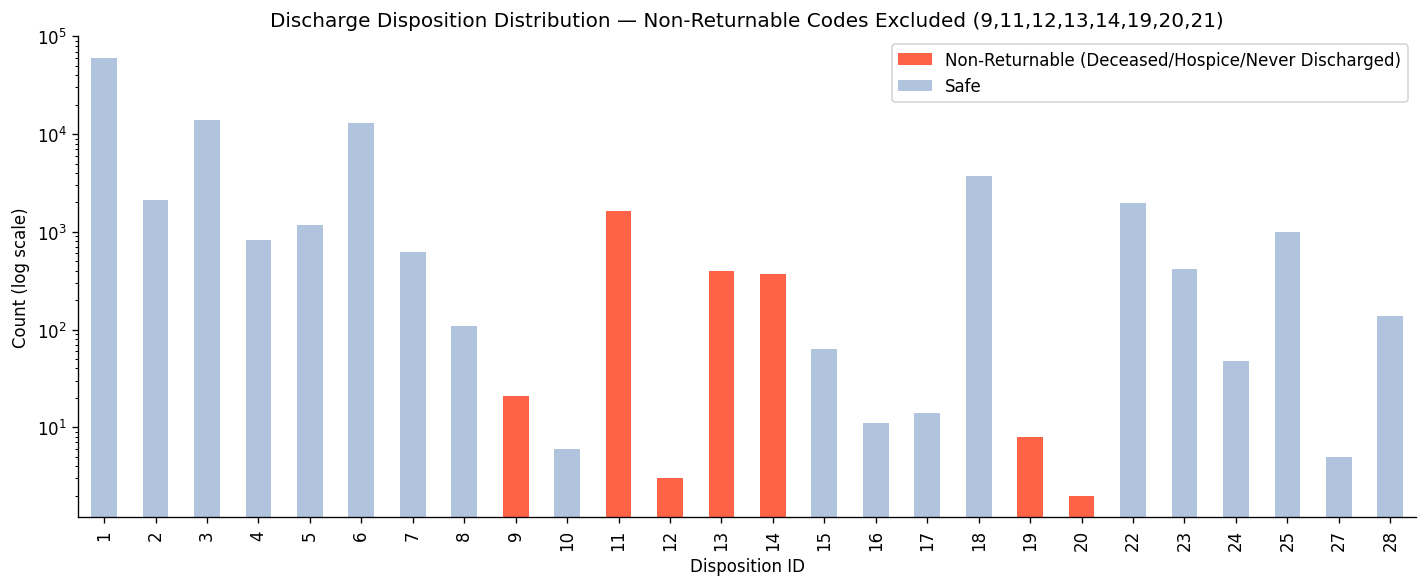

In [9]:
# Visualise leakage risk
# Log scale used to make low-frequency leakage codes visible alongside high-frequency codes
# Red bars = records to be removed before modelling
# Blue bars = retained population
colors = ['tomato' if i in NON_RETURNABLE_CODES else 'lightsteelblue' 
          for i in df['discharge_disposition_id'].value_counts().sort_index().index]

df['discharge_disposition_id'].value_counts().sort_index().plot(
    kind='bar', 
    figsize=(12, 5),
    color=colors
)

legend_elements = [Patch(facecolor='tomato', label='Non-Returnable (Deceased/Hospice/Never Discharged)'),
                   Patch(facecolor='lightsteelblue', label='Safe')]
plt.legend(handles=legend_elements)

plt.title('Discharge Disposition Distribution — Non-Returnable Codes Excluded (9,11,12,13,14,19,20,21)')
plt.xlabel('Disposition ID')
plt.ylabel('Count (log scale)')
plt.yscale('log')
plt.tight_layout()
plt.show()

In [10]:
# Filter non-returnable dispositions before target definition
# Prevents disposition code acting as a proxy for y=0
df = df[~df['discharge_disposition_id'].isin(NON_RETURNABLE_CODES)].copy()

# Verify filter completeness
assert df['discharge_disposition_id'].isin(NON_RETURNABLE_CODES).sum() == 0, \
    "Filter incomplete — non-returnable rows remain"

print(f"Encounters removed: {n_initial - len(df)}")
print(f"Retained population: {len(df)}")

Encounters removed: 2447
Retained population: 99319


### 1.3 Duplicate Patient Check

In [11]:
# Duplicate patient encounter check
# Repeated encounters must be grouped by patient_nbr in the split to prevent the same patient appearing in both sets
print(f"Total encounters: {len(df)}")
print(f"Unique patients: {df['patient_nbr'].nunique()}")
print(f"Duplicate encounters: {len(df) - df['patient_nbr'].nunique()}")
print(f"Duplication rate: {(len(df) - df['patient_nbr'].nunique()) / len(df) * 100:.2f}%")

Total encounters: 99319
Unique patients: 69980
Duplicate encounters: 29339
Duplication rate: 29.54%


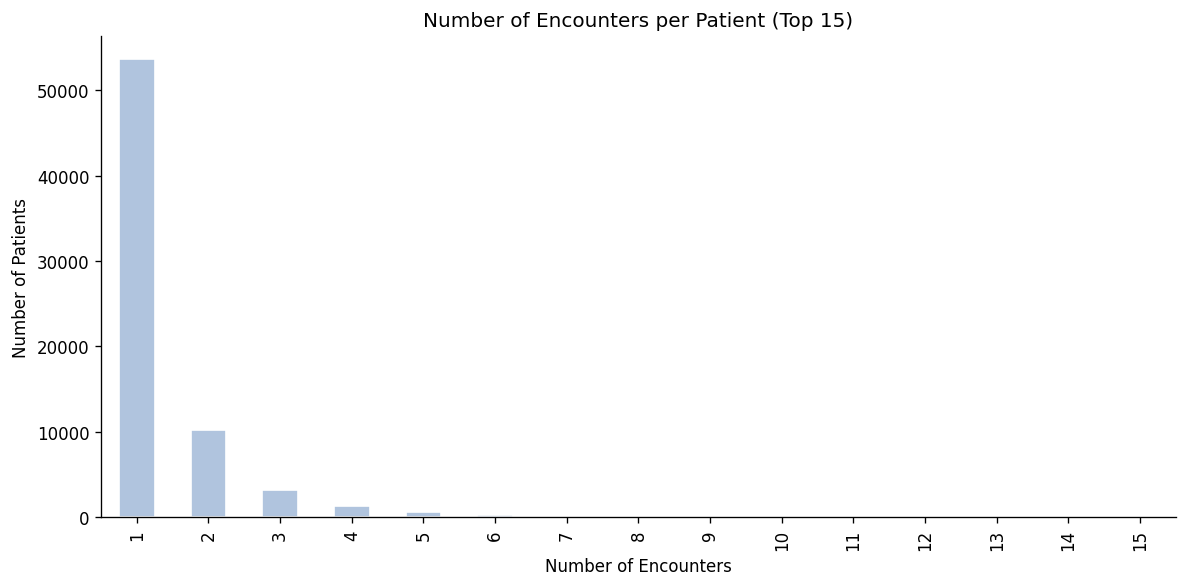


Max encounters for one patient: 40
Average encounters per patient: 1.42


In [12]:
# Distribution of visits per patient
# Confirms most patients appear only once — sharp drop-off after first encounter
visits_per_patient = df['patient_nbr'].value_counts()

plt.figure(figsize=(10, 5))
visits_per_patient.value_counts().sort_index().head(15).plot(
    kind='bar', 
    color='lightsteelblue',
    edgecolor='white'
)
plt.title('Number of Encounters per Patient (Top 15)')
plt.xlabel('Number of Encounters')
plt.ylabel('Number of Patients')
plt.tight_layout()
plt.show()

print(f"\nMax encounters for one patient: {visits_per_patient.max()}")
print(f"Average encounters per patient: {visits_per_patient.mean():.2f}")

### 1.4 Define Binary Target


The primary objective is to predict 30-day unplanned readmissions. Following CMS Hospital 
Readmissions Reduction Program (HRRP) guidelines, the target is defined as:

- **y=1**: Readmitted within 30 days — the clinical event of interest
- **y=0**: Not readmitted, or readmitted after 30 days — stable discharge outcome

Readmissions within 30 days are classified as potentially preventable under HRRP, making 
this threshold the standard quality metric for discharge planning interventions.

In [13]:
# Define binary target based on the 30-day clinical window
# y=1 readmitted within 30 days - represents the clinical event (early readmission)
# y=0: not readmitted OR readmitted after 30 days (acceptable discharge outcome)
df['target'] = (df['readmitted'] == '<30').astype(int)

# Prevalence and imbalance ratio — drives class weight calculation in Step 1.5
prevalence = df['target'].mean()
imbalance_ratio = (1 - prevalence) / prevalence
counts = df['target'].value_counts()

print(f"--- [Target Variable Analysis] ---")
print(f"Class 0 (Negative/Stable):   {counts[0]:>7,} ({1-prevalence:.1%})")
print(f"Class 1 (Positive/At-Risk): {counts[1]:>7,} ({prevalence:.1%})")
print(f"---")
print(f"Imbalance Ratio: {imbalance_ratio:.2f}:1")

--- [Target Variable Analysis] ---
Class 0 (Negative/Stable):    88,016 (88.6%)
Class 1 (Positive/At-Risk):  11,303 (11.4%)
---
Imbalance Ratio: 7.79:1


### 1.5 Compute Balanced Class Weights

Given the established 11.4% prevalence rate, standard classifiers will naturally optimise for accuracy by favouring the majority class (stable discharges). To counteract this bias and align with our clinical goal of maximising sensitivity for high-risk patients, we implement Cost-Sensitive Learning.

We utilise the balanced heuristic to calculate class weights. This mathematically adjusts the loss function of our estimators to penalise errors on the minority class proportionally to its under-representation.

In [14]:
# Strategy: 'balanced' mode uses n_samples / (n_classes * np.bincount(y))
# This ensures the model treats the minority class with equal total importance to the majority.
classes = np.array([0, 1])
weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=df['target']
)

class_weight_dict = {0: round(weights[0], 4), 1: round(weights[1], 4)}

# Verify penalty ratio matches imbalance ratio
print(f"--- [Cost-Sensitive Audit] ---")
print(f"Class 0 weight: {class_weight_dict[0]}")
print(f"Class 1 weight: {class_weight_dict[1]}")
print(f"---")

penalty_ratio = weights[1] / weights[0]
assert round(penalty_ratio, 2) == round(imbalance_ratio, 2), \
    f"Penalty ratio {penalty_ratio:.2f} does not match imbalance ratio {imbalance_ratio:.2f}"
    
print(f"Statistical Penalty Ratio: {weights[1]/weights[0]:.2f}x")
print(f"Inference: The loss function will penalise 'False Negatives' {weights[1]/weights[0]:.1f} times")
print(f"           more heavily than 'False Positives'.")


--- [Cost-Sensitive Audit] ---
Class 0 weight: 0.5642
Class 1 weight: 4.3935
---
Statistical Penalty Ratio: 7.79x
Inference: The loss function will penalise 'False Negatives' 7.8 times
           more heavily than 'False Positives'.


### 1.6 Metric Definitions

- **Primary metric:** F2-score — Recall weighted 2× over Precision.
  A missed readmission (False Negative) carries greater clinical cost than
  a false alarm (False Positive); β=2 directly encodes this asymmetry.

- **Secondary metrics:** ROC-AUC (threshold-independent discrimination),
  Recall (sensitivity to the positive class), Macro F1 (class-balanced
  harmonic mean — penalises models that ignore the minority class entirely).

- **Excluded metric:** Accuracy — invalid under 7.79:1 imbalance. A naive
  classifier predicting the majority class achieves 88.6% without identifying
  a single readmission.

- **Split:** 80/10/10 GroupShuffleSplit by patient_nbr — prevents the same
  patient appearing across train/val/test sets (justified in Step 1.3).

- **FN penalisation cascade:**
  1. class_weight (Step 1.5) — minority class penalty at training time
  2. F2-score (Step 4) — model selection favours high-recall models
  3. Threshold shift (Step 5) — decision boundary lowered to increase sensitivity

## **Step 2: Exploratory Data Analysis (EDA)**

### 2.1 Statistical Summary

In [15]:
# Statistical summary of numerical features
print("Statistical Summary (Numerical):")
df[['time_in_hospital', 'num_lab_procedures', 'num_procedures', 
    'num_medications', 'number_outpatient', 'number_emergency', 
    'number_inpatient', 'number_diagnoses']].describe().round(2)

Statistical Summary (Numerical):


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,99319.00,99319.00,99319.00,99319.00,99319.00,99319.00,99319.00,99319.00
mean,4.38,42.91,1.33,15.98,0.37,0.20,0.63,7.40
std,2.97,19.61,1.70,8.09,1.27,0.94,1.26,1.94
min,1.00,1.00,0.00,1.00,0.00,0.00,0.00,1.00
25%,2.00,31.00,0.00,10.00,0.00,0.00,0.00,6.00
50%,4.00,44.00,1.00,15.00,0.00,0.00,0.00,8.00
75%,6.00,57.00,2.00,20.00,0.00,0.00,1.00,9.00
max,14.00,132.00,6.00,81.00,42.00,76.00,21.00,16.00


In [16]:
# Statistical summary of categorical features
print("Statistical Summary (Categorical):")
df.describe(include='object')

Statistical Summary (Categorical):


,race,gender,age,weight,payer_code,medical_specialty,diag_1,diag_2,diag_3,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
count,97085,99319,99319,3125,59928,50721,99299,98963,97900,5152,16826,99319,99319,99319,99319,99319,99319,99319,99319,99319,99319,99319,99319,99319,99319,99319,99319,99319,99319,99319,99319,99319,99319,99319,99319,99319,99319
unique,5,3,10,9,17,72,715,747,786,3,3,4,4,4,4,4,2,4,4,2,4,4,4,4,2,3,1,1,4,4,2,2,2,2,2,2,3
top,Caucasian,Female,[70-80),[75-100),MC,InternalMedicine,428,276,250,Norm,>8,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
freq,74197,53444,25326,1312,31325,14235,6663,6587,11466,2545,8134,79480,97801,98630,99234,94197,99318,86791,88799,99298,92064,93017,99014,99281,99316,99280,99319,99319,46369,98621,99306,99318,99317,99318,53211,76700,52516


### 2.2 Class Imbalance Visualisation

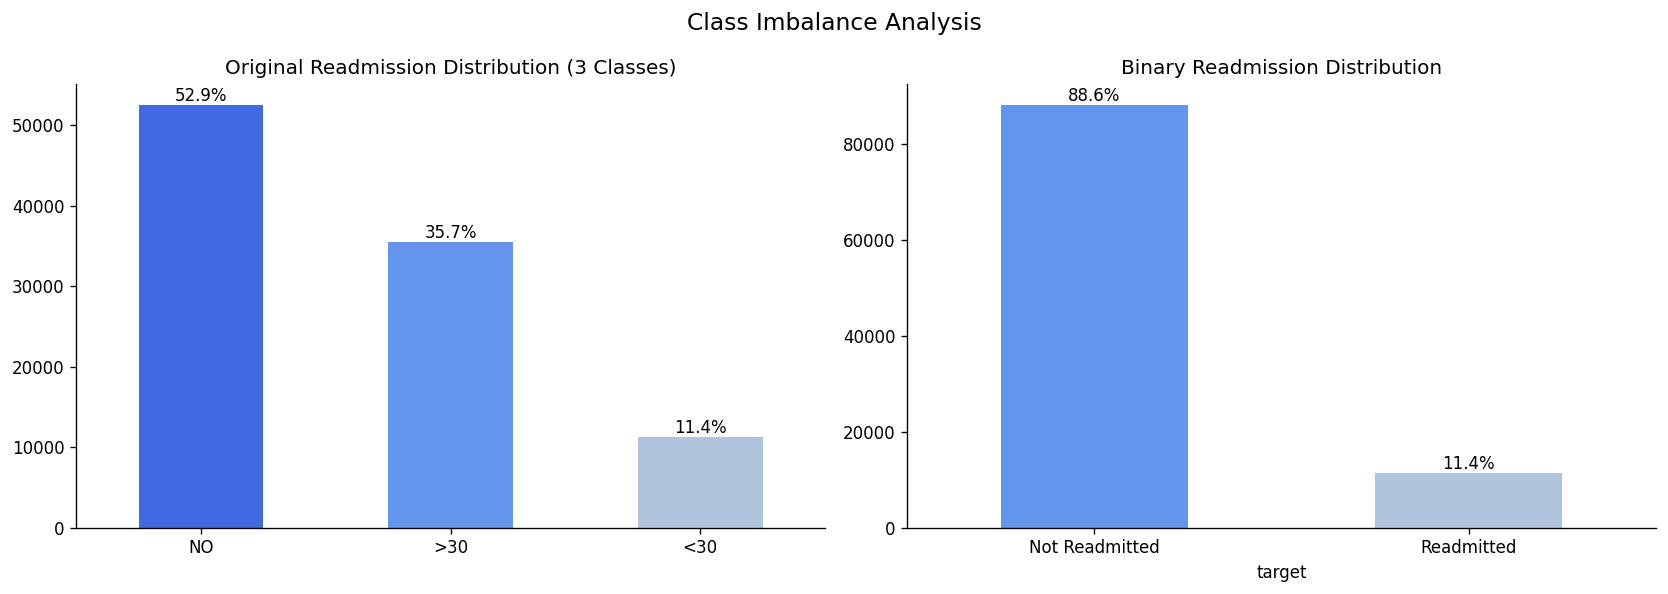

Positive class (<30 days): 11,303 (11.4%)
Negative class:            88,016 (88.6%)
Imbalance ratio:           7.8:1
Consequence: Accuracy is invalid as a metric — F2-score and class weighting required.


In [17]:
# Class imbalance visualisation
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Original 3 Class Distribution
df['readmitted'].value_counts().plot(
    kind='bar', 
    ax=axes[0], 
    color=['royalblue', 'cornflowerblue', 'lightsteelblue']
)
axes[0].set_title('Original Readmission Distribution (3 Classes)')
axes[0].set_xlabel('')
axes[0].tick_params(rotation=0)

# New Binary Target Distribution 
df['target'].value_counts().plot(
    kind='bar', 
    ax=axes[1], 
    color=['cornflowerblue', 'lightsteelblue']
)
axes[1].set_title('Binary Readmission Distribution')
axes[1].set_xticklabels(['Not Readmitted', 'Readmitted'], rotation=0)

for ax in axes:
    for p in ax.patches:
        ax.annotate(f'{p.get_height()/len(df)*100:.1f}%', 
                    (p.get_x() + p.get_width()/2, p.get_height()),
                    ha='center', va='bottom', fontsize=10)

plt.suptitle('Class Imbalance Analysis', fontsize=14)
plt.tight_layout()
plt.show()

# Summary statistics for report'
print(f"Positive class (<30 days): {df['target'].sum():,} ({prevalence:.1%})")
print(f"Negative class:            {(df['target']==0).sum():,} ({1-prevalence:.1%})")
print(f"Imbalance ratio:           {imbalance_ratio:.1f}:1")
print(f"Consequence: Accuracy is invalid as a metric — F2-score and class weighting required.")

### 2.3 Missingness Analysis

In [18]:
# Missingness Summary
missing = df.isnull().sum()
summary = pd.DataFrame({'Missing Count': missing, 'Missing %': missing / len(df) * 100})

missing_summary = summary[summary['Missing Count'] > 0].sort_values('Missing %', ascending=False).round(2)
print(f"Features with missing values: {len(missing_summary)}")
print(missing_summary)

Features with missing values: 9
                   Missing Count  Missing %
weight                     96194      96.85
max_glu_serum              94167      94.81
A1Cresult                  82493      83.06
medical_specialty          48598      48.93
payer_code                 39391      39.66
race                        2234       2.25
diag_3                      1419       1.43
diag_2                       356       0.36
diag_1                        20       0.02


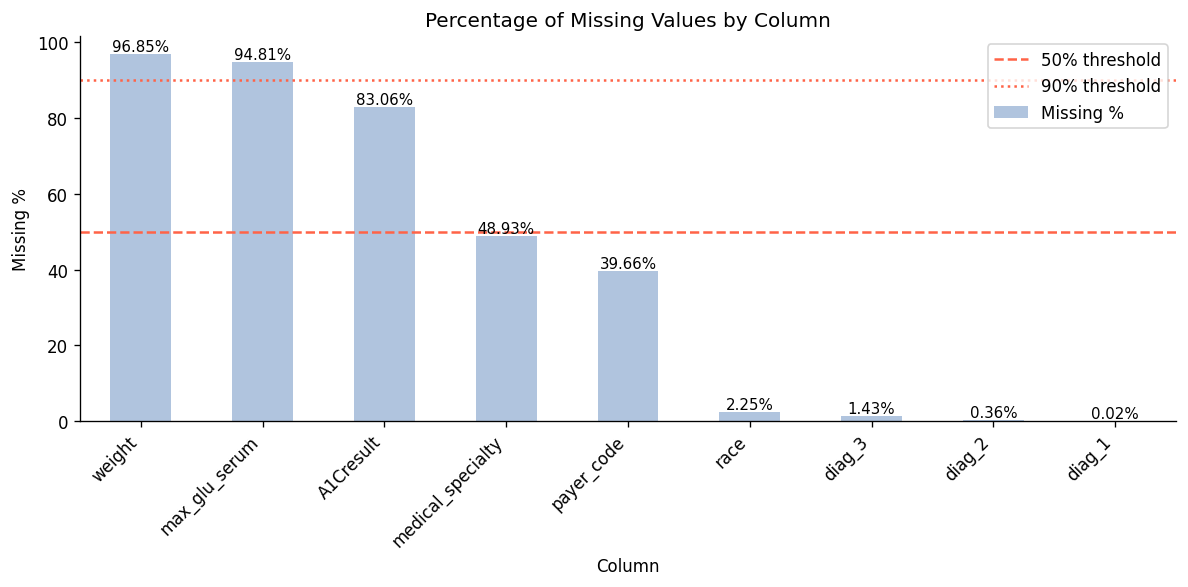

In [19]:
# Visualise missingness - Bar Chart
# 50% threshold: conventional rule — features missing in majority of rows are unlikely to be reliably imputable
# 90% threshold: near-complete absence — imputation would be speculation,not inference. Columns above this line are candidates for dropping.
plt.figure(figsize=(10, 5))
ax = missing_summary['Missing %'].plot(kind='bar', color='lightsteelblue')
plt.axhline(y=50, color='tomato', linestyle='--', label='50% threshold')
plt.axhline(y=90, color='tomato', linestyle=':', label='90% threshold')
plt.title('Percentage of Missing Values by Column')
plt.xlabel('Column')
plt.ylabel('Missing %')
plt.xticks(rotation=45, ha='right')
plt.legend()

for p in ax.patches:
    ax.annotate(f'{p.get_height():.2f}%',
                (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

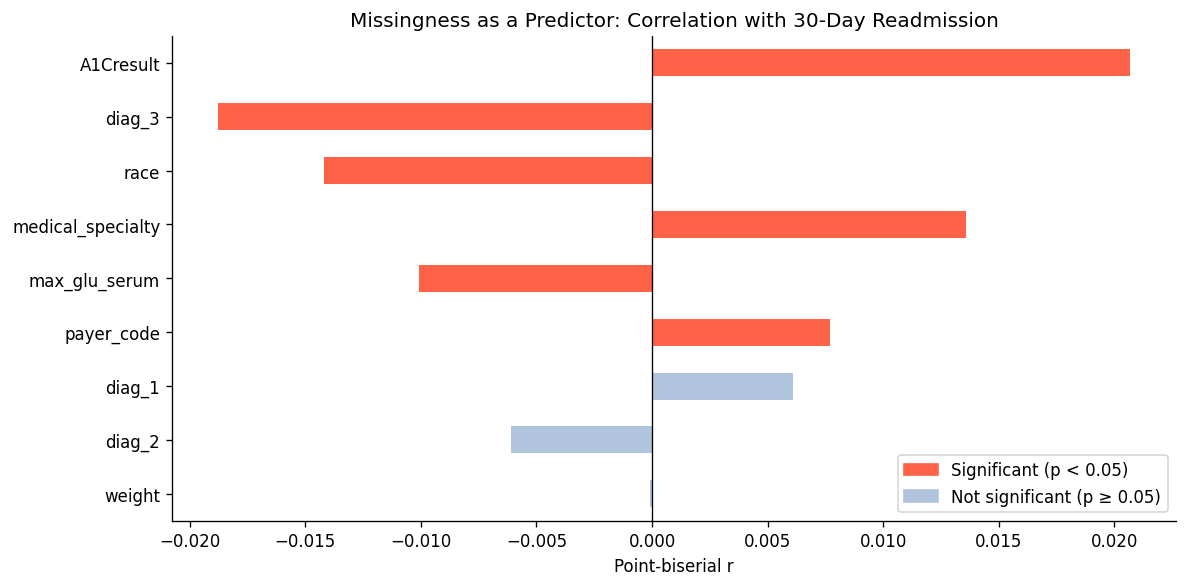

                        r       p
weight            -0.0001  0.9836
diag_2            -0.0061  0.0542
diag_1             0.0061  0.0551
payer_code         0.0077  0.0150
max_glu_serum     -0.0101  0.0015
medical_specialty  0.0136  0.0000
race              -0.0142  0.0000
diag_3            -0.0188  0.0000
A1Cresult          0.0207  0.0000


In [20]:
# Visual missingness - Point-biserial correlation audit
# predictive signal — known as 'informative missingness' (Rubin, 1976).
# p < 0.05: missingness is non-random with respect to the target (MNAR)
# p >= 0.05: missingness is unrelated to target (MAR or MCAR)
# All |r| values < 0.1 confirms no leakage from missingness indicators
miss_signal = {}
for col in missing_summary.index:
    r, p = pointbiserialr(df['target'], df[col].isnull().astype(int))
    miss_signal[col] = {'r': round(r, 4), 'p': round(p, 4)}

miss_signal_df = pd.DataFrame(miss_signal).T.sort_values('r', key=abs)

colors = ['tomato' if p < 0.05 else 'lightsteelblue' 
          for p in miss_signal_df['p']]

miss_signal_df['r'].plot(kind='barh', figsize=(10, 5), color=colors)
plt.axvline(0, color='black', linewidth=0.8)

plt.title('Missingness as a Predictor: Correlation with 30-Day Readmission')
plt.xlabel('Point-biserial r')
plt.legend(handles=[
    plt.Rectangle((0,0),1,1, color='tomato', label='Significant (p < 0.05)'),
    plt.Rectangle((0,0),1,1, color='lightsteelblue', label='Not significant (p ≥ 0.05)')
], loc='lower right')
plt.tight_layout()
plt.show()

print(miss_signal_df)

### 2.4 Categorical Feature Distributions

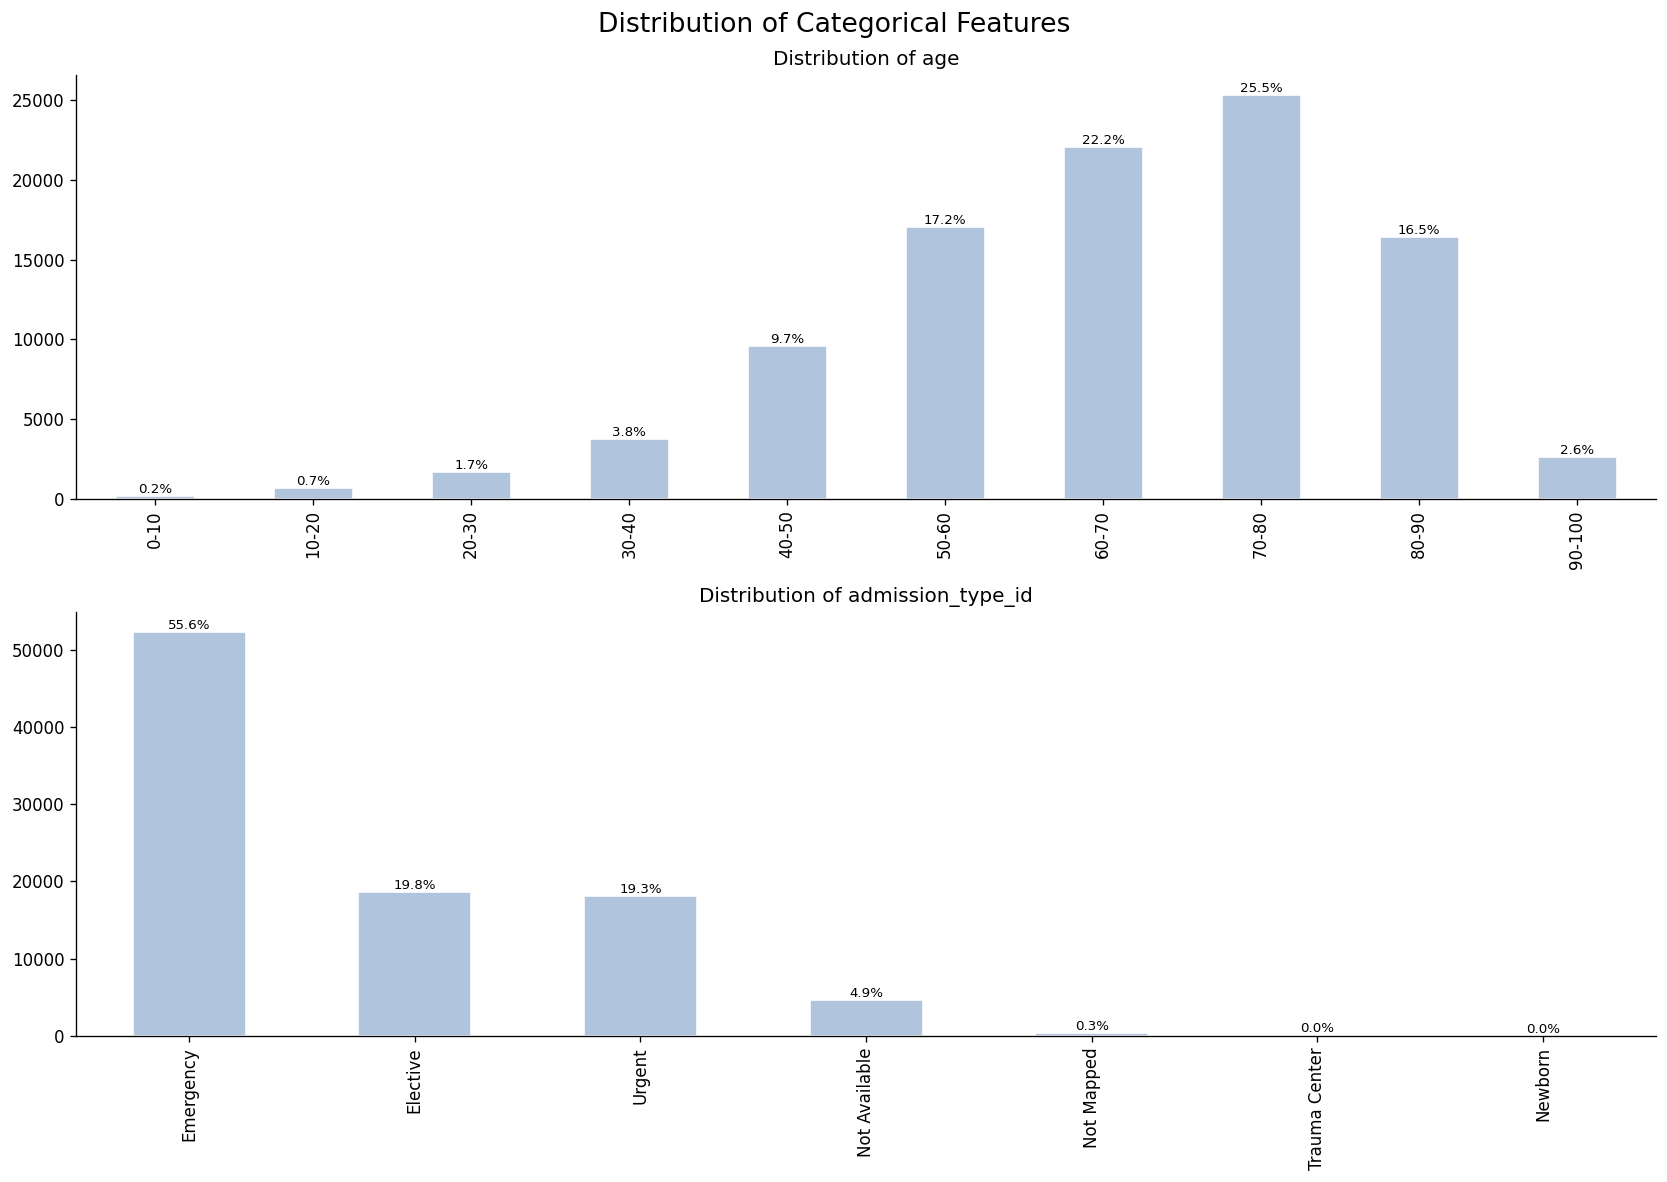

In [21]:
# Feature distribution - Categorical features
categorical_cols = ['age', 'admission_type_id']

# age: ordinal variable with natural ordering
age_order = ['[0-10)', '[10-20)', '[20-30)', '[30-40)', '[40-50)', 
             '[50-60)', '[60-70)', '[70-80)', '[80-90)', '[90-100)']


age_labels = {
    '[0-10)': '0-10', '[10-20)': '10-20', '[20-30)': '20-30',
    '[30-40)': '30-40', '[40-50)': '40-50', '[50-60)': '50-60',
    '[60-70)': '60-70', '[70-80)': '70-80', '[80-90)': '80-90',
    '[90-100)': '90-100'
}

fig, axes = plt.subplots(2, figsize=(14, 10))
for ax, col in zip(axes.flatten(), categorical_cols):
    if col == 'admission_type_id':
        mapped = df[col].map(admission_type_map.set_index('admission_type_id')['description'])
        counts = mapped.value_counts()
    elif col == 'age':
        counts = df[col].value_counts().reindex(age_order)
        counts.index = counts.index.map(age_labels)  # remap for display only
    else:
        counts = df[col].value_counts()
    
    counts.plot(kind='bar', ax=ax, color='lightsteelblue', edgecolor='white')
    ax.set_title(f'Distribution of {col}')
    ax.set_xlabel('')
    
    # Add percentage labels
    total = counts.sum()
    for p in ax.patches:
        ax.annotate(f'{p.get_height()/total*100:.1f}%',
                    (p.get_x() + p.get_width()/2, p.get_height()),
                    ha='center', va='bottom', fontsize=8)

plt.suptitle('Distribution of Categorical Features', fontsize=16)
plt.tight_layout()
plt.show()

### 2.5 Numerical Feature Distributions

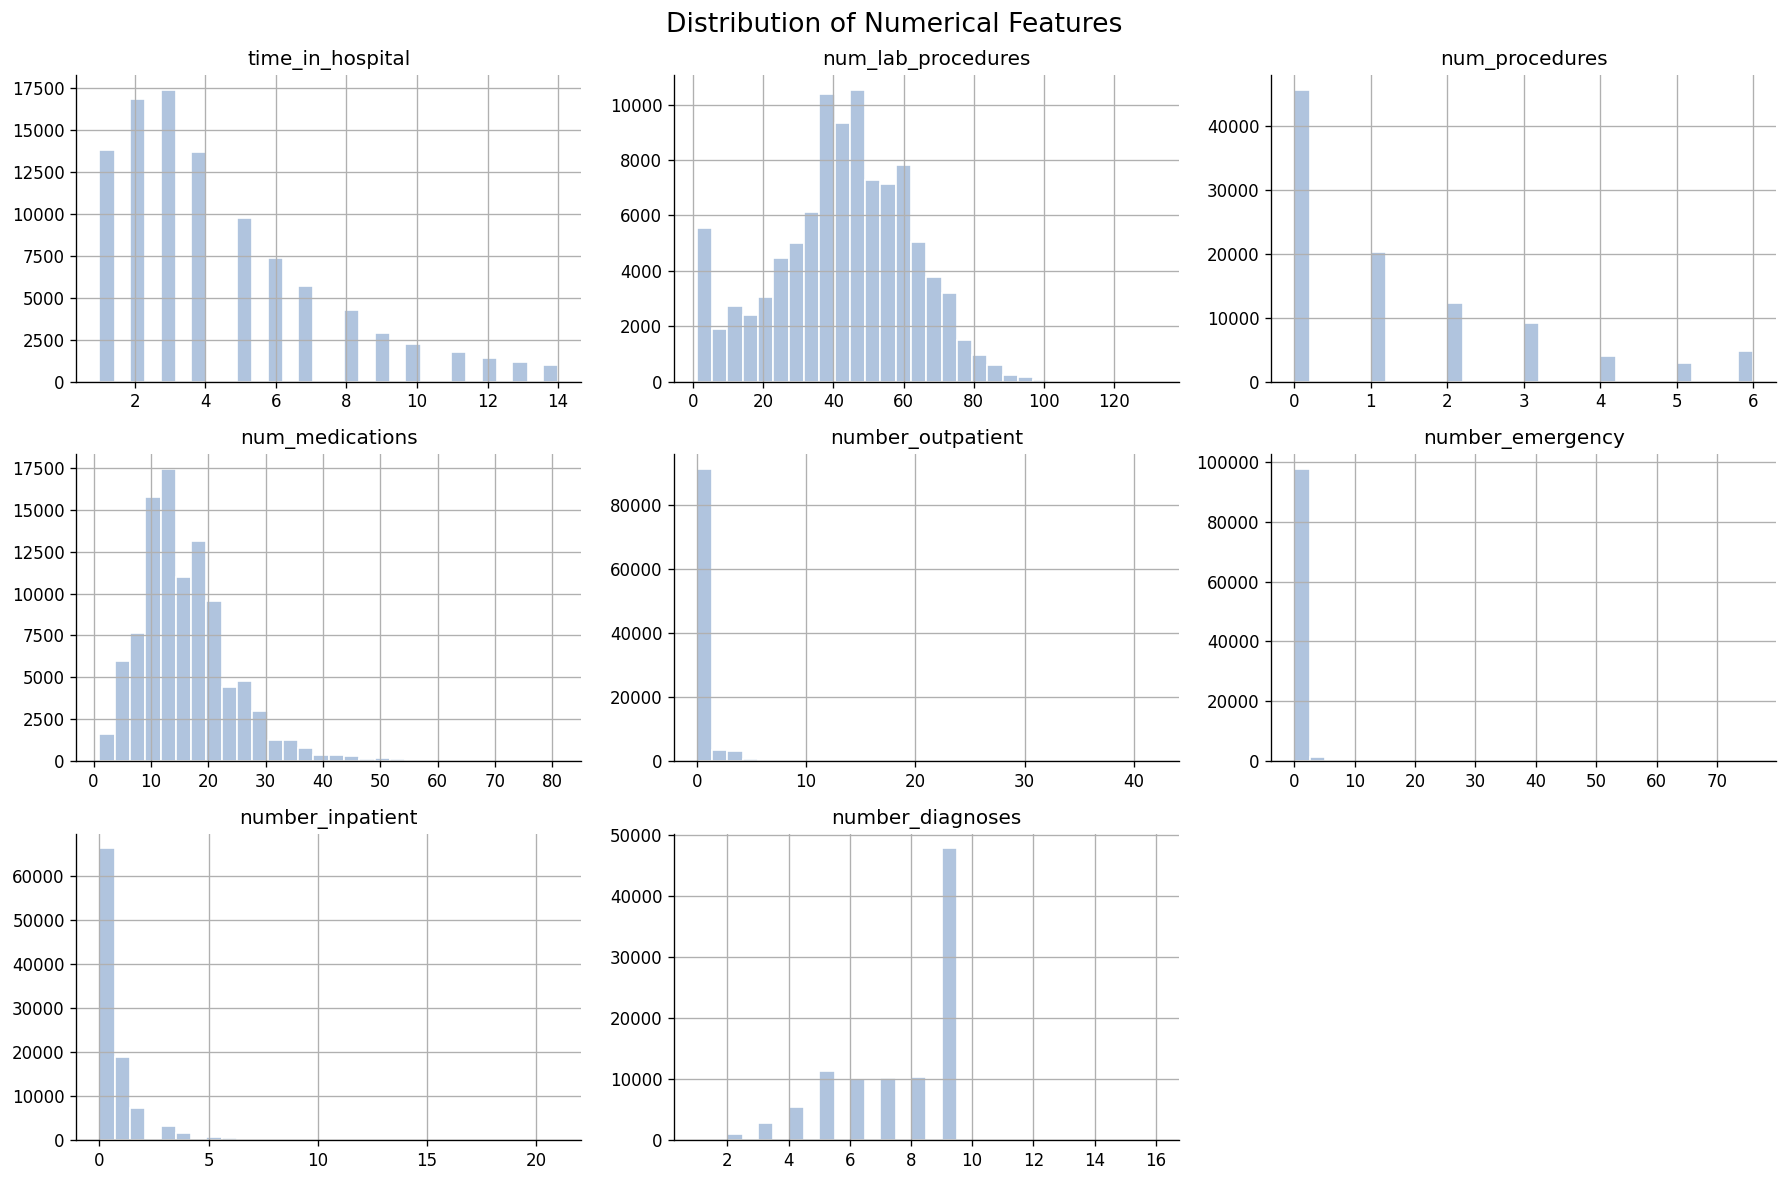

In [22]:
# Feature distribution - numerical features
numerical_cols = [
    'time_in_hospital',      # number of days admitted
    'num_lab_procedures',    # number of lab tests performed
    'num_procedures',        # number of procedures performed
    'num_medications',       # number of medications administered
    'number_outpatient',     # outpatient visits in previous year
    'number_emergency',      # emergency visits in previous year
    'number_inpatient',      # inpatient visits in previous year
    'number_diagnoses'       # number of diagnoses entered
]
# 1. Identify distributional shape
# 2. Detect zero-inflation in prior visit counts
# 3. Flag anomalous patterns
df[numerical_cols].hist(bins=30, figsize=(15, 10), color='lightsteelblue', edgecolor='white')  # plot all numerical distributions
plt.suptitle('Distribution of Numerical Features', fontsize=16)
plt.tight_layout()
plt.show()

### 2.6 Outlier Detection

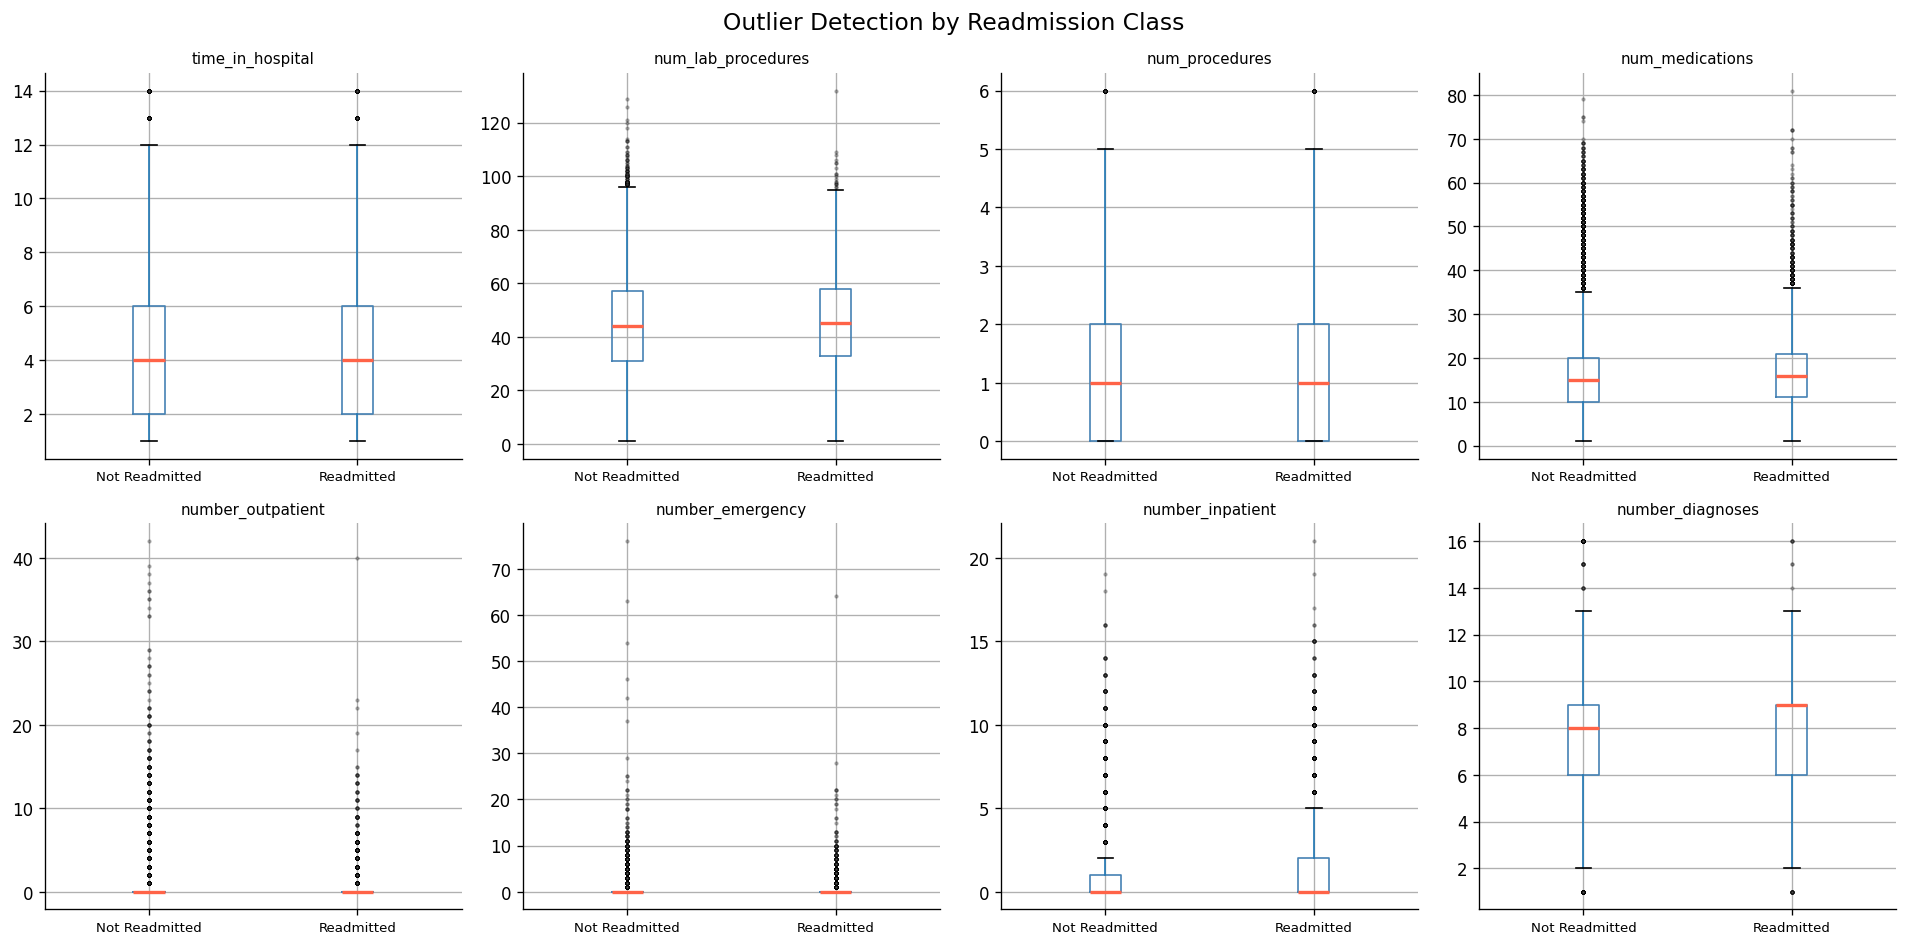

In [23]:
# Box Plots — numerical features split by readmission class
# Reveals whether outlier patterns differ between readmitted and non-readmitted patients
# Red line = median, blue box = interquartile range, grey dots = outliers
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, col in zip(axes.flatten(), numerical_cols):
    df.boxplot(column=col, by='target', ax=ax,
               boxprops=dict(color='steelblue'),
               medianprops=dict(color='tomato', linewidth=2),
               flierprops=dict(marker='.', markerfacecolor='grey', markersize=3, alpha=0.3))
    ax.set_title(col, fontsize=9)
    ax.set_xlabel('')
    ax.set_xticklabels(['Not Readmitted', 'Readmitted'], fontsize=8)

plt.suptitle('Outlier Detection by Readmission Class', fontsize=14)
plt.tight_layout()
plt.show()

### 2.7 Near-Zero Variance Analysis

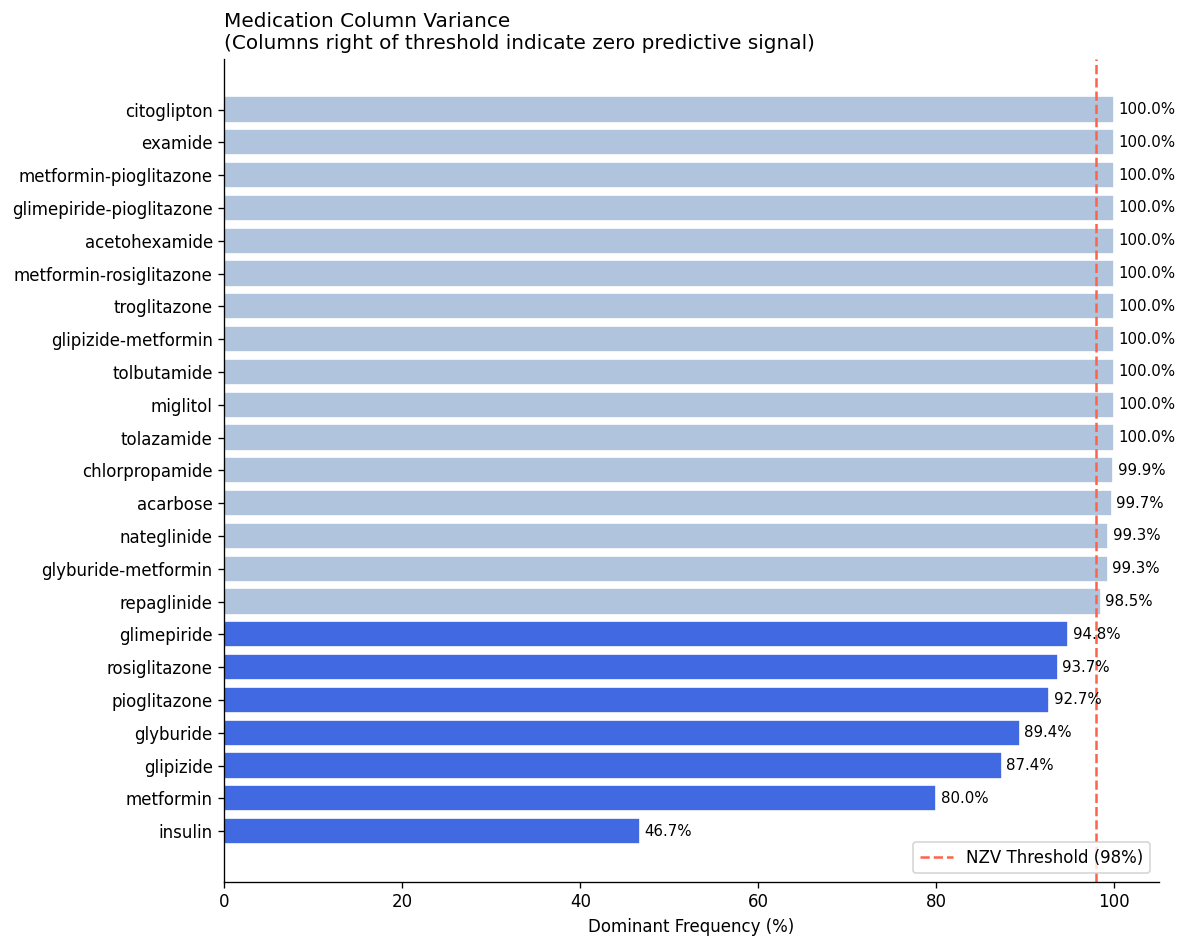

--- [Variance Audit: Final Decision] ---
NZV columns to DROP (16): ['repaglinide', 'glyburide-metformin', 'nateglinide', 'acarbose', 'chlorpropamide', 'tolazamide', 'miglitol', 'tolbutamide', 'glipizide-metformin', 'troglitazone', 'metformin-rosiglitazone', 'acetohexamide', 'glimepiride-pioglitazone', 'metformin-pioglitazone', 'examide', 'citoglipton']
Medication columns to KEEP (9): ['metformin', 'glimepiride', 'glipizide', 'glyburide', 'pioglitazone', 'rosiglitazone', 'insulin', 'change', 'diabetesMed']


In [24]:
# NZV analysis on medication columns only

med_cols = [
    'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
    'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
    'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
    'tolazamide', 'examide', 'citoglipton', 'insulin',
    'glyburide-metformin', 'glipizide-metformin',
    'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone'
]

# dominant_freq: proportion of rows taking the most common value
# A feature with dominant_freq >= 0.98 provides near-zero discriminative signal
# — the model cannot learn meaningful patterns from a feature that is constant
# in 98%+ of training examples (Kuhn & Johnson, 2013)
med_var_df = pd.DataFrame({
    'dominant_freq': [df[col].value_counts(normalize=True).iloc[0] for col in med_cols],
    'dominant_level': [df[col].value_counts().index[0] for col in med_cols],
    'n_levels': [df[col].nunique() for col in med_cols]
}, index=med_cols).sort_values('dominant_freq', ascending=True)

# NZV_THRESHOLD = 0.98: Kuhn & Johnson (2013) recommended threshold repaglinide (98.5%) is the marginal case — clearly exceeds threshold
NZV_THRESHOLD = 0.98
nzv_mask = med_var_df['dominant_freq'] >= NZV_THRESHOLD


colors = ['lightsteelblue' if val >= NZV_THRESHOLD else 'royalblue' 
          for val in med_var_df['dominant_freq']]

fig, ax = plt.subplots(figsize=(10, 8))


ax.barh(med_var_df.index, med_var_df['dominant_freq'] * 100, 
        color=colors, edgecolor='white')


ax.axvline(NZV_THRESHOLD * 100, color='tomato', linestyle='--', 
           linewidth=1.5, label=f'NZV Threshold ({NZV_THRESHOLD * 100:.0f}%)')


ax.set_xlabel('Dominant Frequency (%)')
ax.set_title('Medication Column Variance\n(Columns right of threshold indicate zero predictive signal)', loc='left')
ax.legend(loc='lower right')


for i, val in enumerate(med_var_df['dominant_freq']):
    ax.text(val * 100 + 0.5, i, f'{val*100:.1f}%', va='center', fontsize=9)

plt.tight_layout()
plt.show()

# Execution logic
NZV_COLS = med_var_df[med_var_df['dominant_freq'] >= NZV_THRESHOLD].index.tolist()
MED_COLS_KEEP = [c for c in med_cols if c not in NZV_COLS] + ['change', 'diabetesMed']

print(f"--- [Variance Audit: Final Decision] ---")
print(f"NZV columns to DROP ({len(NZV_COLS)}): {NZV_COLS}")
print(f"Medication columns to KEEP ({len(MED_COLS_KEEP)}): {MED_COLS_KEEP}")

In [25]:
# Inspect the full distribution to make an informed decision
# Kuhn & Johnson (2013) 
med_var_df[['dominant_freq', 'n_levels']].sort_values('dominant_freq').round(4)

,dominant_freq,n_levels
insulin,0.4669,4
metformin,0.8002,4
glipizide,0.8739,4
glyburide,0.8941,4
pioglitazone,0.9270,4
rosiglitazone,0.9365,4
glimepiride,0.9484,4
repaglinide,0.9847,4
glyburide-metformin,0.9930,4
nateglinide,0.9931,4


### 2.8 Subgroup Analysis

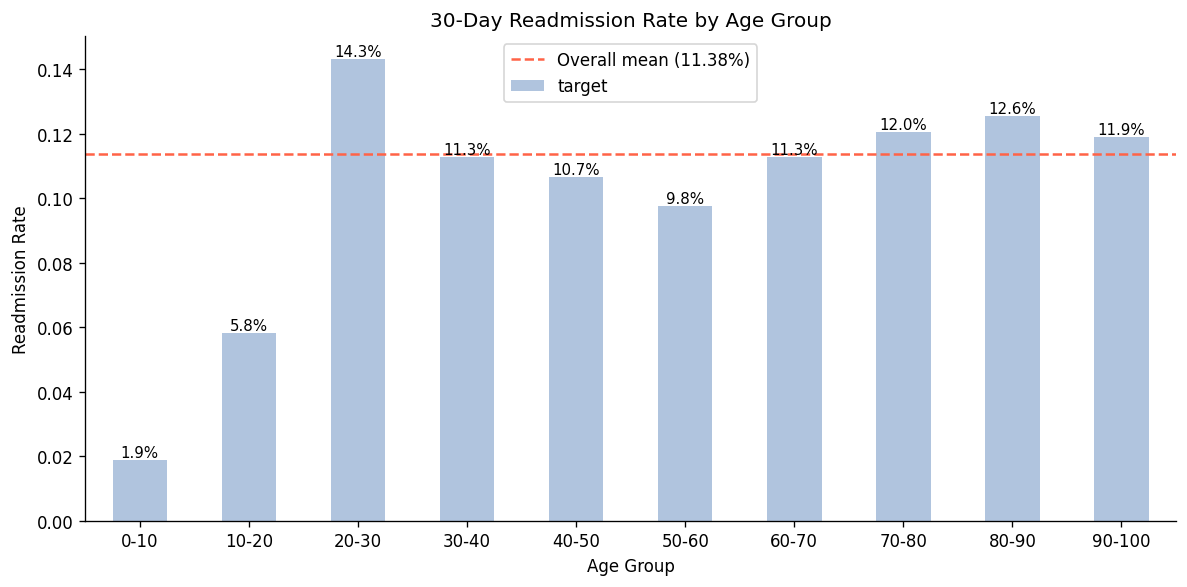

In [26]:
# Readmission rate by age group
# Reveals whether age is associated with 30-day readmission risk
ax = (df.groupby('age')['target']
      .mean()
      .reindex(age_order)
      .rename(index=age_labels)  # remap for display only
      .plot(kind='bar', color='lightsteelblue', figsize=(10, 5)))

for p in ax.patches:
    ax.annotate(f'{p.get_height():.1%}', 
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom', fontsize=9)

plt.axhline(y=df['target'].mean(), color='tomato', 
            linestyle='--', label=f'Overall mean ({df["target"].mean():.2%})')
plt.title('30-Day Readmission Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Readmission Rate')
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

### 2.9 Correlation Analysis

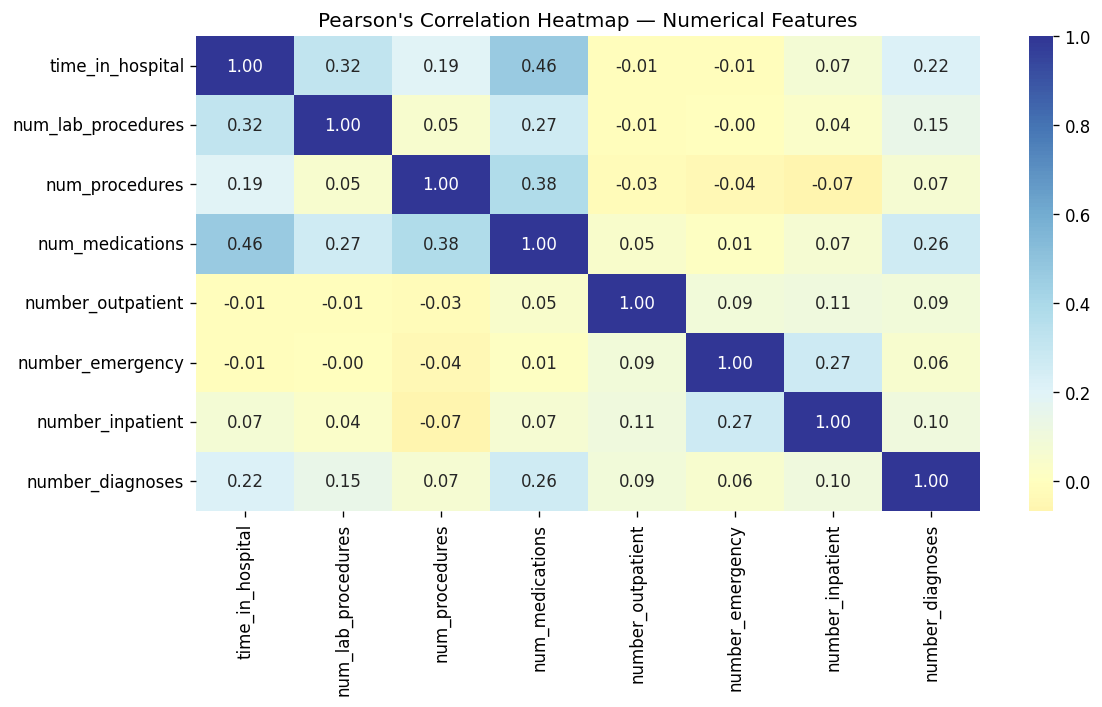

In [27]:
# Pearson Correlation Heatmap
# Identifies multicollinearity: pairs above |r|>0.8 indicate redundant features that inflate coefficient variance in linear models (Kutner et al., 2004)
# Near-zero correlations between prior visit counts and in-hospital features confirm independence of feature groups
plt.figure(figsize=(10, 6))
sns.heatmap(
    df[numerical_cols].corr(), 
    annot=True, 
    fmt='.2f', 
    cmap='RdYlBu',
    center=0
)
plt.title('Pearson\'s Correlation Heatmap — Numerical Features')
plt.tight_layout()
plt.show()

## **Step 3: Data Preparation**

### 3.1 Features List

In [28]:
# Missing Value Audit (pre-processing baseline)
# Documents missingness before any transformations are applied
print(f"\nMissing values before preprocessing:")
print(df.isnull().sum()[df.isnull().sum() > 0])


Missing values before preprocessing:
race                  2234
weight               96194
payer_code           39391
medical_specialty    48598
diag_1                  20
diag_2                 356
diag_3                1419
max_glu_serum        94167
A1Cresult            82493
dtype: int64


In [29]:
# Columns to drop 
DROP_COLS = [
    # Identifiers
    'encounter_id', 'patient_nbr',
    # Target source — must never be a feature
    'readmitted',
    # High missingness(96.9%), missingness signal p=0.984 (EDA 2.3)
    'weight',
    # Missing and non-informative (EDA 2.3)
    'medical_specialty', 'payer_code',
    # 16 near-zero variance medication columns (EDA 2.7)(Kuhn & Johnson, 2013)
    'repaglinide', 'glyburide-metformin', 'nateglinide', 'acarbose',
    'chlorpropamide', 'tolazamide', 'miglitol', 'tolbutamide',
    'glipizide-metformin', 'troglitazone', 'metformin-rosiglitazone',
    'acetohexamide', 'glimepiride-pioglitazone', 'metformin-pioglitazone',
    'examide', 'citoglipton'
]

print(f"Columns to drop: {len(DROP_COLS)}")

Columns to drop: 22


In [30]:
# Feature Group Definitions

# Approximately normal distributions (EDA 2.5)
CONTINUOUS_COLS = [
    'time_in_hospital', 'num_lab_procedures', 'num_procedures',
    'num_medications', 'number_diagnoses'
]

# Severely right-skewed, zero-inflated (EDA 2.5, 2.6)
LOG_COLS = [
    'number_outpatient', 'number_emergency', 'number_inpatient'
]

# age brackets with natural ordering (EDA 2.4)
ORDINAL_COLS = ['age']

AGE_MAP = {
    '[0-10)': 0, '[10-20)': 1, '[20-30)': 2, '[30-40)': 3, '[40-50)': 4,
    '[50-60)': 5, '[60-70)': 6, '[70-80)': 7, '[80-90)': 8, '[90-100)': 9
}

# High missingness with informative signal (EDA 2.3)
LAB_COLS = ['A1Cresult', 'max_glu_serum']

# ICD-9 codes requiring clinical grouping
DIAG_COLS = ['diag_1', 'diag_2', 'diag_3']

# Nominal categorical features
OHE_COLS = [
    'race', 'gender', 'admission_type_id', 'discharge_disposition_id',
    'admission_source_id', 'metformin', 'glimepiride', 'glipizide',
    'glyburide', 'pioglitazone', 'rosiglitazone', 'insulin',
    'change', 'diabetesMed'
]

print(f"CONTINUOUS:  {len(CONTINUOUS_COLS)} columns")
print(f"LOG:         {len(LOG_COLS)} columns")
print(f"ORDINAL:     {len(ORDINAL_COLS)} columns")
print(f"LAB:         {len(LAB_COLS)} columns")
print(f"DIAG (ICD):  {len(DIAG_COLS)} columns")
print(f"OHE:         {len(OHE_COLS)} columns")


CONTINUOUS:  5 columns
LOG:         3 columns
ORDINAL:     1 columns
LAB:         2 columns
DIAG (ICD):  3 columns
OHE:         14 columns


### 3.2 Drop Columns + Target and Identifier Separation

In [31]:
# Leakage prevention step

# patient_nbr excluded from X — identifier leakage risk
X = df.drop(columns=[c for c in DROP_COLS if c != 'patient_nbr'] + ['target']).copy()

# binary target — aligned with X by shared index
y = df['target'].copy()

# used by GroupShuffleSplit only — discarded after splitting
groups = df['patient_nbr'].copy()

print(f"X shape before preprocessing: {X.shape}")
print(f"y shape: {y.shape}")
print(f"Unique patients for grouping: {groups.nunique():,}")

X shape before preprocessing: (99319, 29)
y shape: (99319,)
Unique patients for grouping: 69,980


In [32]:
# Verification: medical_specialty and payer_code successfully dropped
assert 'medical_specialty' not in X.columns, "medical_specialty still present in X!"
assert 'payer_code' not in X.columns, "payer_code still present in X!"
print("Non-informative column drop verification: PASSED")

Non-informative column drop verification: PASSED


In [33]:
# Data Quality Validation  
# Checks the quality and integrity of the data

def validate_data(df, stage=""):
    """Run validation checks and report issues."""
    checks = []
    
    # Check 1: No duplicate encounter IDs - avoid inflating metrics if same row appears in train and test
    dup_encounters = df['encounter_id'].duplicated().sum()
    checks.append(('Duplicate encounters', dup_encounters, dup_encounters == 0))
    
    # Check 2: Target variable is binary - confirms population filter did not corrupt target definition
    target_values = df['target'].unique()
    checks.append(('Target is binary', len(target_values), len(target_values) == 2))
    
    # Check 3: No negative values in count features - physiologically impossible; indicates data corruption
    count_cols = ['num_lab_procedures', 'num_procedures', 'num_medications', 
                  'number_outpatient', 'number_emergency', 'number_inpatient']
    neg_counts = sum((df[col] < 0).sum() for col in count_cols if col in df.columns)
    checks.append(('Negative counts', neg_counts, neg_counts == 0))
    
    # Check 4: Time in hospital within reasonable range -  1-14 days is the dataset constraint per Strack et al. (2014)
    if 'time_in_hospital' in df.columns:
        out_of_range = ((df['time_in_hospital'] < 1) | (df['time_in_hospital'] > 14)).sum()
        checks.append(('Hospital stay 1-14 days', out_of_range, out_of_range == 0))
    
    print(f"Data Validation — {stage}")
    print("-" * 50)
    for check_name, value, passed in checks:
        status = "✓ PASS" if passed else "✗ FAIL"
        print(f"{status}: {check_name} = {value}")
    print()
    
    return all(passed for _, _, passed in checks)

validate_data(df, stage="Pre-Split Baseline")

Data Validation — Pre-Split Baseline
--------------------------------------------------
✓ PASS: Duplicate encounters = 0
✓ PASS: Target is binary = 2
✓ PASS: Negative counts = 0
✓ PASS: Hospital stay 1-14 days = 0



True

### 3.3 Train / Validation / Test Split

In [34]:
# Pre-Split Pipeline Validation 
# checks for misalignment and leakage before splitting:

# Check 1: X and y have the same number of rows
assert len(X) == len(y), f"X and y row mismatch: {len(X)} vs {len(y)}"
print(f"Pre-split Check 1 — X and y aligned: {len(X):,} rows each: PASSED")

# Check 2: No target leakage — readmitted must not be in X
assert 'readmitted' not in X.columns, "Target leakage: readmitted column present in X!"
print(f"Pre-split Check 2 — No target leakage: PASSED")

# Check 3: Identifiers dropped except patient_nbr (needed for grouping)
assert 'encounter_id' not in X.columns, "encounter_id still present in X!"
print(f"Pre-split Check 3 — encounter_id removed: PASSED")

# Check 4: groups aligns with X
assert len(groups) == len(X), "groups length does not match X!"
print(f"Pre-split Check 4 — groups aligned with X: {groups.nunique():,} unique patients: PASSED")

# Check 5: No all-NaN columns entering the split
all_nan_cols = X.columns[X.isna().all()].tolist()
assert len(all_nan_cols) == 0, f"All-NaN columns present: {all_nan_cols}"
print(f"Pre-split Check 5 — No all-NaN columns: PASSED")

print(f"\nAll pre-split checks passed. Proceeding to split.")

Pre-split Check 1 — X and y aligned: 99,319 rows each: PASSED
Pre-split Check 2 — No target leakage: PASSED
Pre-split Check 3 — encounter_id removed: PASSED
Pre-split Check 4 — groups aligned with X: 69,980 unique patients: PASSED
Pre-split Check 5 — No all-NaN columns: PASSED

All pre-split checks passed. Proceeding to split.


In [35]:
# Two-stage split required for 80/10/10
# GroupShuffleSplit by patient_nbr prevents same patient appearing in multiple splits

# Step 1: carve out 10% test
gss_test = GroupShuffleSplit(n_splits=1, test_size=0.10, random_state=RANDOM_STATE)
trainval_idx, test_idx = next(gss_test.split(X, y, groups=groups))

X_trainval, X_test = X.iloc[trainval_idx].copy(), X.iloc[test_idx].copy()
y_trainval, y_test = y.iloc[trainval_idx].copy(), y.iloc[test_idx].copy()
groups_trainval = groups.iloc[trainval_idx]

# Step 2: carve out 10% validation from remaining 90%
gss_val = GroupShuffleSplit(n_splits=1, test_size=1/9, random_state=RANDOM_STATE)
train_idx, val_idx = next(gss_val.split(X_trainval, y_trainval, groups=groups_trainval))

X_train = X_trainval.iloc[train_idx].copy()
X_val   = X_trainval.iloc[val_idx].copy()
y_train = y_trainval.iloc[train_idx].copy()
y_val   = y_trainval.iloc[val_idx].copy()

In [36]:
# Post-Split Validation

# Validation Check 1: No patient overlap across splits 
train_patients = set(X_train['patient_nbr'])
val_patients   = set(X_val['patient_nbr'])
test_patients  = set(X_test['patient_nbr'])

assert train_patients.isdisjoint(val_patients),  "Patient overlap: train ∩ val!"
assert train_patients.isdisjoint(test_patients), "Patient overlap: train ∩ test!"
assert val_patients.isdisjoint(test_patients),   "Patient overlap: val ∩ test!"
print("Validation Check 1 — No patient overlap: PASSED")

# Validation Check 2: Target rate consistency - imbalance is not concentrated in one split
print(f"\nValidation Check 2 — Target rate consistency:")
print(f"  Train positive rate: {y_train.mean():.1%}  (expected ~11%)")
print(f"  Val positive rate:   {y_val.mean():.1%}  (expected ~11%)")
print(f"  Test positive rate:  {y_test.mean():.1%}  (expected ~11%)")

# Validation Check 3: Split ratio 
total = len(X_train) + len(X_val) + len(X_test)
print(f"\nValidation Check 3 — Split ratio:")
print(f"  Train: {len(X_train):,} ({len(X_train)/total*100:.1f}%)  — target 80%")
print(f"  Val:   {len(X_val):,} ({len(X_val)/total*100:.1f}%)  — target 10%")
print(f"  Test:  {len(X_test):,} ({len(X_test)/total*100:.1f}%)  — target 10%")

# Drop patient_nbr after grouping is complete, identifier must not enter modelling
X_train = X_train.drop(columns=['patient_nbr'])
X_val   = X_val.drop(columns=['patient_nbr'])
X_test  = X_test.drop(columns=['patient_nbr'])
print(f"\npatient_nbr dropped from feature matrix.")

Validation Check 1 — No patient overlap: PASSED

Validation Check 2 — Target rate consistency:
  Train positive rate: 11.5%  (expected ~11%)
  Val positive rate:   10.8%  (expected ~11%)
  Test positive rate:  11.3%  (expected ~11%)

Validation Check 3 — Split ratio:
  Train: 79,568 (80.1%)  — target 80%
  Val:   9,888 (10.0%)  — target 10%
  Test:  9,863 (9.9%)  — target 10%

patient_nbr dropped from feature matrix.


In [37]:
# Store original maxes before transformation — used in verification below
original_maxes = {col: df[col].max() for col in LOG_COLS}

 **If any transformation was fitted on the full dataset before splitting, the test set has already influenced the pipeline**

### 3.4 ICD Diagnosis Grouping (CCS)

In [38]:
# Numeric ranges follow CCS chapter boundaries (Strack et al., 2014)
# Applied identically to train, val, test — no leakage risk
def map_icd_to_ccs(code):
    """
    Maps an ICD-9 code string to a CCS chapter label.
    Handles:
    # 1. NaN → 'Unknown' (diag_1 has 20 missing, diag_3 has 1,419)
    # 2. E/V codes → 'External_Supplementary' (injury causes, supplementary classification)
    # 3. Non-numeric strings → 'Unknown' via ValueError catch
    """
    if pd.isna(code):
        return 'Unknown'
    code = str(code).strip()

    if code.startswith('E') or code.startswith('V'):
        return 'External_Supplementary'

    try:
        num = float(code)
    except ValueError:
        return 'Unknown'

    if   num < 140:  return 'Infectious_Parasitic'
    elif num < 240:  return 'Neoplasms'
    elif num < 280:  return 'Endocrine_Metabolic'
    elif num < 290:  return 'Blood_Disorders'
    elif num < 320:  return 'Mental_Disorders'
    elif num < 390:  return 'Nervous_System'
    elif num < 460:  return 'Circulatory'
    elif num < 520:  return 'Respiratory'
    elif num < 580:  return 'Digestive'
    elif num < 630:  return 'Genitourinary'
    elif num < 680:  return 'Pregnancy_Childbirth'
    elif num < 710:  return 'Skin_Subcutaneous'
    elif num < 740:  return 'Musculoskeletal'
    elif num < 760:  return 'Congenital_Anomalies'
    elif num < 780:  return 'Perinatal'
    elif num < 800:  return 'Symptoms_Illdefined'
    elif num < 1000: return 'Injury_Poisoning'
    else:            return 'Unknown'

# Apply to train — then val and test (no fit required, deterministic mapping)
for col in DIAG_COLS:
    X_train[col] = X_train[col].apply(map_icd_to_ccs)
    X_val[col]   = X_val[col].apply(map_icd_to_ccs)
    X_test[col]  = X_test[col].apply(map_icd_to_ccs)

# Verification: confirm expected categories
ccs_categories = X_train['diag_1'].value_counts()
print(f"CCS categories found in diag_1: {X_train['diag_1'].nunique()}")
print(ccs_categories)

CCS categories found in diag_1: 18
diag_1
Circulatory               23746
Endocrine_Metabolic        9095
Respiratory                7955
Digestive                  7237
Symptoms_Illdefined        6060
Injury_Poisoning           5494
Genitourinary              3996
Musculoskeletal            3973
Neoplasms                  2512
Infectious_Parasitic       2038
Skin_Subcutaneous          1973
Mental_Disorders           1785
External_Supplementary     1294
Nervous_System              937
Blood_Disorders             874
Pregnancy_Childbirth        543
Congenital_Anomalies         41
Unknown                      15
Name: count, dtype: int64


In [39]:
# Verification
coverage = (X_train['diag_1'] != 'Unknown').mean()
assert coverage > 0.999, f"ICD coverage below threshold: {coverage:.4f}"
print(f"ICD-9 mapping coverage: {coverage:.2%}")

ICD-9 mapping coverage: 99.98%


### 3.5 Imputation

In [40]:
# Race Imputation
# race: 1,919 missing (1.9%) — impute with mode from train only
# Mode computed on X_train — applied to val and test to prevent leakage
race_mode = X_train['race'].mode()[0]

for split in [X_train, X_val, X_test]:
    split['race'].fillna(race_mode, inplace=True)

assert X_train['race'].isna().sum() == 0, "NaN values remain in race (train)!"
assert X_val['race'].isna().sum() == 0,   "NaN values remain in race (val)!"
assert X_test['race'].isna().sum() == 0,  "NaN values remain in race (test)!"
print(f"race imputed with mode: '{race_mode}'")

race imputed with mode: 'Caucasian'


### 3.6 Feature Encoding

In [41]:
# Lab Result Encoding
# Missingness is a clinical signal (patient was not tested), not random noise
# NaN and string 'None' both map to 'Not_Tested' preserves the clinical signal: patient was not tested, not that result is missing
# Applied identically to train, val, test — no fit required
for col in LAB_COLS:
    for split in [X_train, X_val, X_test]:
        split[col] = split[col].fillna('Not_Tested').replace('None', 'Not_Tested')

print("Lab result encoding complete.")
print(f"A1Cresult levels:     {sorted(X_train['A1Cresult'].unique())}")
print(f"max_glu_serum levels: {sorted(X_train['max_glu_serum'].unique())}")

Lab result encoding complete.
A1Cresult levels:     ['>7', '>8', 'Norm', 'Not_Tested']
max_glu_serum levels: ['>200', '>300', 'Norm', 'Not_Tested']


In [42]:
# Verification: no NaN remain and Not_Tested present in all splits
for split_name, split in [('train', X_train), ('val', X_val), ('test', X_test)]:
    for col in LAB_COLS:
        assert split[col].isna().sum() == 0, f"NaN remains in {col} ({split_name})!"
        assert 'Not_Tested' in split[col].values, f"Not_Tested missing from {col} ({split_name})!"
print("Lab encoding verification: PASSED — no NaN, Not_Tested present across all splits")

Lab encoding verification: PASSED — no NaN, Not_Tested present across all splits


In [43]:
# Verification
for col in LAB_COLS:
    assert X_train[col].isna().sum() == 0, f"NaN remains in {col} after encoding"
print("Lab encoding assertions: PASSED")

Lab encoding assertions: PASSED


In [44]:
# Ordinal Age Encoding
# Age: ordered string brackets mapped to integers 0–9 via AGE_MAP (defined in 3.1)
# Assertion confirms AGE_MAP covers all values present in the data
for split in [X_train, X_val, X_test]:
    split['age'] = split['age'].map(AGE_MAP)

# Verification
assert X_train['age'].isna().sum() == 0, "Unmapped age values present!"
print(f"Age encoding complete. Range: {X_train['age'].min()}–{X_train['age'].max()}")


Age encoding complete. Range: 0–9


### 3.7 Log Transformation

In [45]:
# Severe right skew and zero-inflation confirmed in EDA (2.5, 2.6)
# log(x+1) handles zero values — confirmed present in all three columns
# Fitted on train values only — applied identically to val and test
for col in LOG_COLS:
    for split in [X_train, X_val, X_test]:
        split[col] = np.log1p(split[col])

print("Log(x+1) transformation applied to:")
print(f"  {LOG_COLS}")
print(f"\nPost-transform means (train):")
for col in LOG_COLS:
    print(f"  {col}: {X_train[col].mean():.4f}")

Log(x+1) transformation applied to:
  ['number_outpatient', 'number_emergency', 'number_inpatient']

Post-transform means (train):
  number_outpatient: 0.1718
  number_emergency: 0.1052
  number_inpatient: 0.3254


In [46]:
# Verification: confirm skew reduction — max values compressed
for col in LOG_COLS:
    original_max = df[col].max()
    transformed_max = X_train[col].max()
    print(f"{col}: original max={original_max:.1f} → transformed max={transformed_max:.4f} (log scale)")
    assert transformed_max < original_max, f"log(x+1) did not compress {col}!"
print("Log transformation skew compression: CONFIRMED")

number_outpatient: original max=42.0 → transformed max=3.7612 (log scale)
number_emergency: original max=76.0 → transformed max=4.3438 (log scale)
number_inpatient: original max=21.0 → transformed max=3.0910 (log scale)
Log transformation skew compression: CONFIRMED


### 3.8 StandardScaler 

In [47]:
# Fitted on X_train only  — mean and std estimated from train
# Applied to val and test using train parameters
# Prevents test distribution leaking into scaling parameters

scaler = StandardScaler()
scale_cols = CONTINUOUS_COLS + LOG_COLS

X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_val[scale_cols]   = scaler.transform(X_val[scale_cols])
X_test[scale_cols]  = scaler.transform(X_test[scale_cols])

# Verification: train means should be ~0, stds ~1
print("Scaler fitted on train only.")
print(f"Post-scale train means (should be ~0): {X_train[scale_cols].mean().round(4).values}")
print(f"Post-scale train stds  (should be ~1): {X_train[scale_cols].std().round(4).values}")

Scaler fitted on train only.
Post-scale train means (should be ~0): [-0.  0.  0.  0. -0. -0.  0.  0.]
Post-scale train stds  (should be ~1): [1. 1. 1. 1. 1. 1. 1. 1.]


### 3.9 One-Hot Encoding (OHE)

In [48]:
# Applied to LAB_COLS, DIAG_COLS, and OHE_COLS.
# Fitted on X_train — handles unseen categories in val/test via handle_unknown
# drop='first': removes one dummy per feature — avoids perfect multicollinearity

ohe_target_cols = LAB_COLS + DIAG_COLS + OHE_COLS

encoder = OneHotEncoder(
    drop='first',
    sparse_output=False,
    handle_unknown='ignore'
)

# Fit on train
ohe_train = encoder.fit_transform(X_train[ohe_target_cols])
ohe_val   = encoder.transform(X_val[ohe_target_cols])
ohe_test  = encoder.transform(X_test[ohe_target_cols])

ohe_feature_names = encoder.get_feature_names_out(ohe_target_cols)

# Replace original columns with encoded versions
X_train = pd.concat([
    X_train.drop(columns=ohe_target_cols).reset_index(drop=True),
    pd.DataFrame(ohe_train, columns=ohe_feature_names)
], axis=1)

X_val = pd.concat([
    X_val.drop(columns=ohe_target_cols).reset_index(drop=True),
    pd.DataFrame(ohe_val, columns=ohe_feature_names)
], axis=1)

X_test = pd.concat([
    X_test.drop(columns=ohe_target_cols).reset_index(drop=True),
    pd.DataFrame(ohe_test, columns=ohe_feature_names)
], axis=1)

print(f"OHE complete. Features generated: {len(ohe_feature_names)}")


OHE complete. Features generated: 127


### 3.10 Validation Checks

In [49]:
# Confirms pipeline integrity before modelling
assert X_train.shape[1] == X_val.shape[1] == X_test.shape[1], \
    "Feature matrix shape mismatch across splits!"

# No remaining NaN values
assert X_train.isna().sum().sum() == 0, "NaN values present in X_train!"
assert X_val.isna().sum().sum()   == 0, "NaN values present in X_val!"
assert X_test.isna().sum().sum()  == 0, "NaN values present in X_test!"

# Target rate consistency
print(f"--- [Step 3 Complete — Validation Summary] ---")
print(f"X_train: {X_train.shape}  |  y_train positive rate: {y_train.mean():.1%}")
print(f"X_val:   {X_val.shape}  |  y_val positive rate:   {y_val.mean():.1%}")
print(f"X_test:  {X_test.shape}  |  y_test positive rate:  {y_test.mean():.1%}")
print(f"No patient overlap: CONFIRMED")
print(f"Scaler fitted on train only: CONFIRMED")
print(f"No NaN values remaining: CONFIRMED")
print(f"\nReady for Step 4: Modelling")

--- [Step 3 Complete — Validation Summary] ---
X_train: (79568, 136)  |  y_train positive rate: 11.5%
X_val:   (9888, 136)  |  y_val positive rate:   10.8%
X_test:  (9863, 136)  |  y_test positive rate:  11.3%
No patient overlap: CONFIRMED
Scaler fitted on train only: CONFIRMED
No NaN values remaining: CONFIRMED

Ready for Step 4: Modelling


In [50]:
# Identifier check: confirms encounter_id and patient_nbr were successfully dropped
assert 'encounter_id' not in X_train.columns, "encounter_id present in X_train!"
assert 'patient_nbr' not in X_train.columns, "patient_nbr present in X_train!"
print("Identifier check: PASSED")

# Scaler verification: n_samples_seen_ == len(X_train) confirms fit-on-train guarantee
assert int(scaler.n_samples_seen_) == len(X_train), \
    f"Scaler was fitted on {scaler.n_samples_seen_} rows — expected {len(X_train)} (train only)!"
print(f"Scaler fit-on-train verification: PASSED ({scaler.n_samples_seen_:,} train rows)")

Identifier check: PASSED
Scaler fit-on-train verification: PASSED (79,568.0 train rows)


## **Step 4: Modelling**

### 4.1 Evaluation Function

In [51]:
# Primary metric: F2-score 
# Secondary: ROC-AUC, Recall, Macro F1
# Excluded: Accuracy (invalid under class imbalance)

# Single function applied identically to all models
def evaluate_model(model, X, y, model_name="Model", split_name="Validation"):
    """
    Evaluates a fitted model on a given split.
    Returns a results dictionary for use in the comparison table.
    """
    y_pred  = model.predict(X)
    y_proba = model.predict_proba(X)[:, 1]

    # beta=2: recall weighted 2x over precision — primary metric (Step 1)
    f2       = fbeta_score(y, y_pred, beta=2)
    auc      = roc_auc_score(y, y_proba)
    recall   = recall_score(y, y_pred)
    # average='macro': equal weight per class — penalises ignoring minority class
    macro_f1 = f1_score(y, y_pred, average='macro')

    print(f"\n{'='*55}")
    print(f"{model_name} — {split_name} Results")
    print(f"{'='*55}")
    print(f"  F2-Score  (primary):   {f2:.4f}")
    print(f"  ROC-AUC:               {auc:.4f}")
    print(f"  Recall (<30d class):   {recall:.4f}")
    print(f"  Macro F1:              {macro_f1:.4f}")
    print(f"\nClassification Report:")
    print(classification_report(y, y_pred, target_names=['Not Readmitted', 'Readmitted']))

    # Confusion matrix
    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay.from_predictions(
    y, y_pred,
    display_labels=['Not Readmitted', 'Readmitted'],
    ax=ax, colorbar=False,
    cmap='Blues'
    )
    
    ax.set_title(f'{model_name} — Confusion Matrix ({split_name})')
    plt.tight_layout()
    plt.show()

    # Returns dict for aggregation into comparison table
    return {
        'Model':    model_name,
        'F2':       round(f2, 4),
        'ROC-AUC':  round(auc, 4),
        'Recall':   round(recall, 4),
        'Macro F1': round(macro_f1, 4)
    }

### 4.2 Logistic Regression 


Logistic Regression — Validation Results
  F2-Score  (primary):   0.3761
  ROC-AUC:               0.6500
  Recall (<30d class):   0.5440
  Macro F1:              0.5185

Classification Report:
                precision    recall  f1-score   support

Not Readmitted       0.92      0.67      0.78      8820
    Readmitted       0.17      0.54      0.26      1068

      accuracy                           0.66      9888
     macro avg       0.55      0.61      0.52      9888
  weighted avg       0.84      0.66      0.72      9888



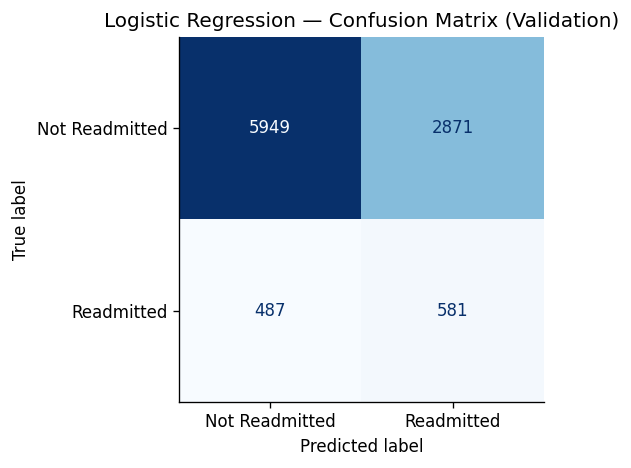

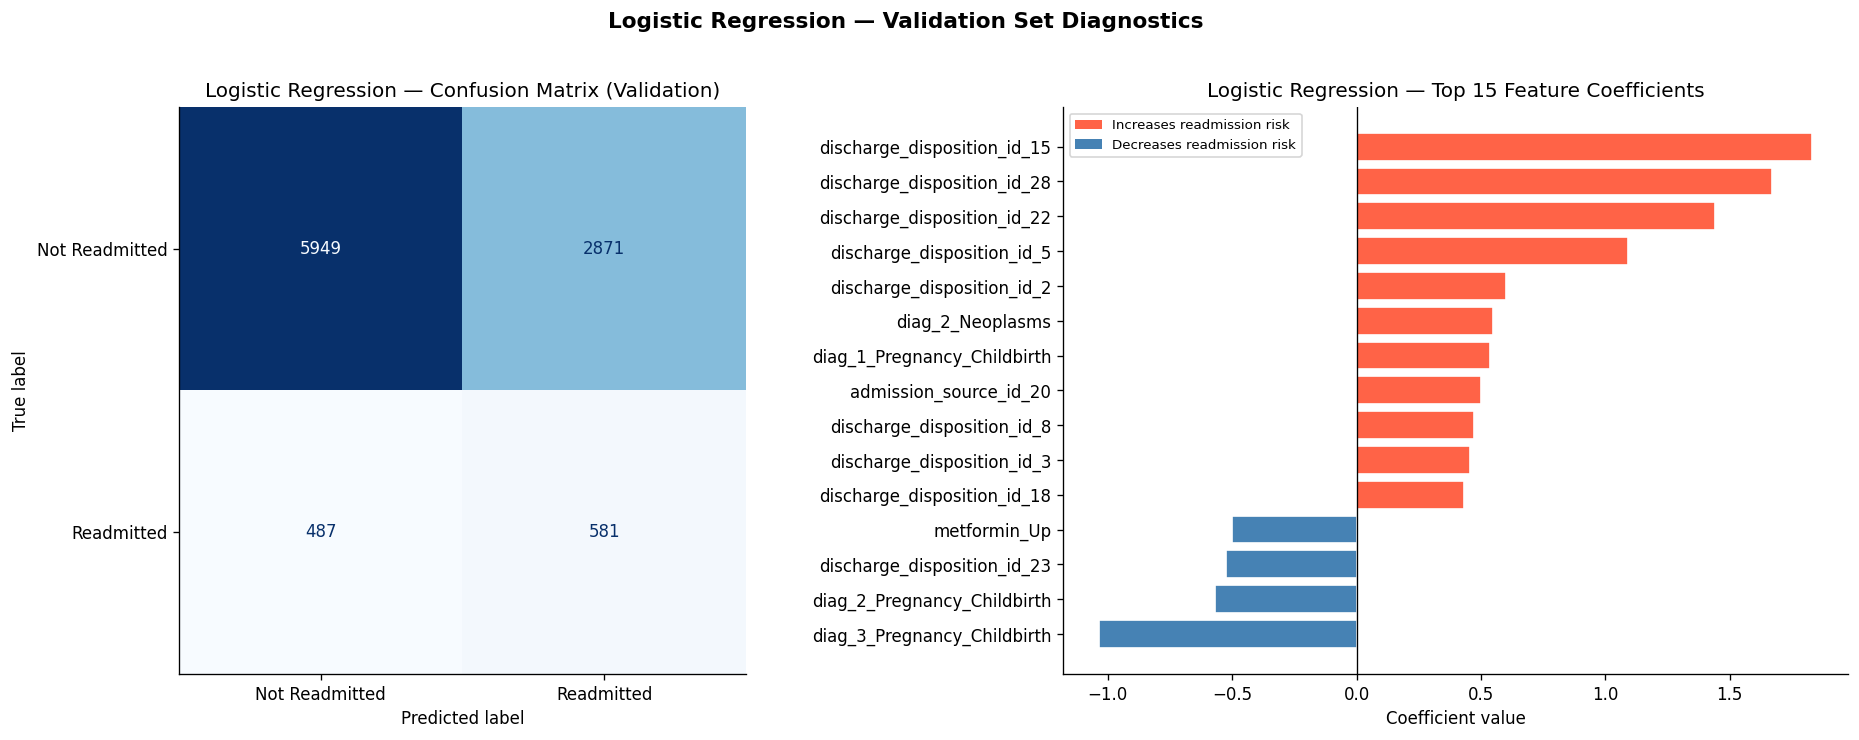

In [52]:
# Logistic Regression — baseline model
# class_weight=class_weight_dict: penalises FN more heavily than FP
# max_iter=1000: default 100 insufficient for convergence on 136 features
lr = LogisticRegression(
    class_weight=class_weight_dict,
    max_iter=1000,
    random_state=RANDOM_STATE
)

# Evaluated on validation set only — test set not touched at this stage
lr.fit(X_train, y_train)
lr_results = evaluate_model(lr, X_val, y_val, model_name="Logistic Regression")

# Coefficient interpretation: top 15 features by absolute weight
coef_df = pd.DataFrame({
    'feature': X_train.columns,
    'coefficient': lr.coef_[0]
})
coef_df['abs_coefficient'] = coef_df['coefficient'].abs()
coef_df = coef_df.sort_values('abs_coefficient', ascending=False).head(15)
coef_df = coef_df.sort_values('coefficient', ascending=True)

colors = ['tomato' if c > 0 else 'steelblue' for c in coef_df['coefficient']]

# Confusion matrix data
lr_pred_val = lr.predict(X_val)
cm = confusion_matrix(y_val, lr_pred_val)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel 1: Confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, 
                               display_labels=['Not Readmitted', 'Readmitted'])
disp.plot(ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title('Logistic Regression — Confusion Matrix (Validation)')

# Panel 2: Coefficient plot
axes[1].barh(coef_df['feature'], coef_df['coefficient'], color=colors, edgecolor='white')
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].set_title('Logistic Regression — Top 15 Feature Coefficients')
axes[1].set_xlabel('Coefficient value')

legend_elements = [Patch(facecolor='tomato', label='Increases readmission risk'),
                   Patch(facecolor='steelblue', label='Decreases readmission risk')]
axes[1].legend(handles=legend_elements, fontsize=8)

plt.suptitle('Logistic Regression — Validation Set Diagnostics', 
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


### 4.3 XGBoost


XGBoost — Validation Results
  F2-Score  (primary):   0.3458
  ROC-AUC:               0.6332
  Recall (<30d class):   0.4691
  Macro F1:              0.5275

Classification Report:
                precision    recall  f1-score   support

Not Readmitted       0.92      0.72      0.81      8820
    Readmitted       0.17      0.47      0.25      1068

      accuracy                           0.69      9888
     macro avg       0.54      0.59      0.53      9888
  weighted avg       0.84      0.69      0.75      9888



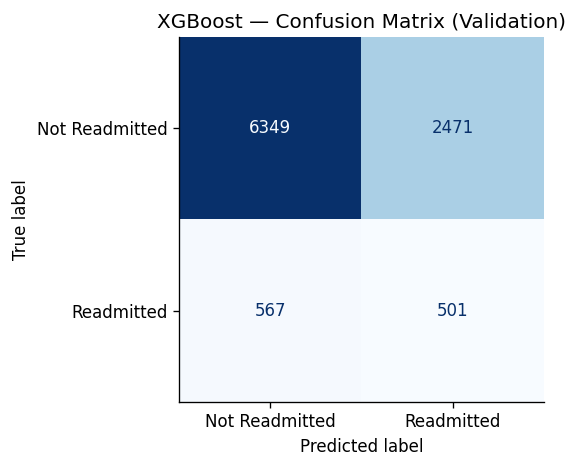

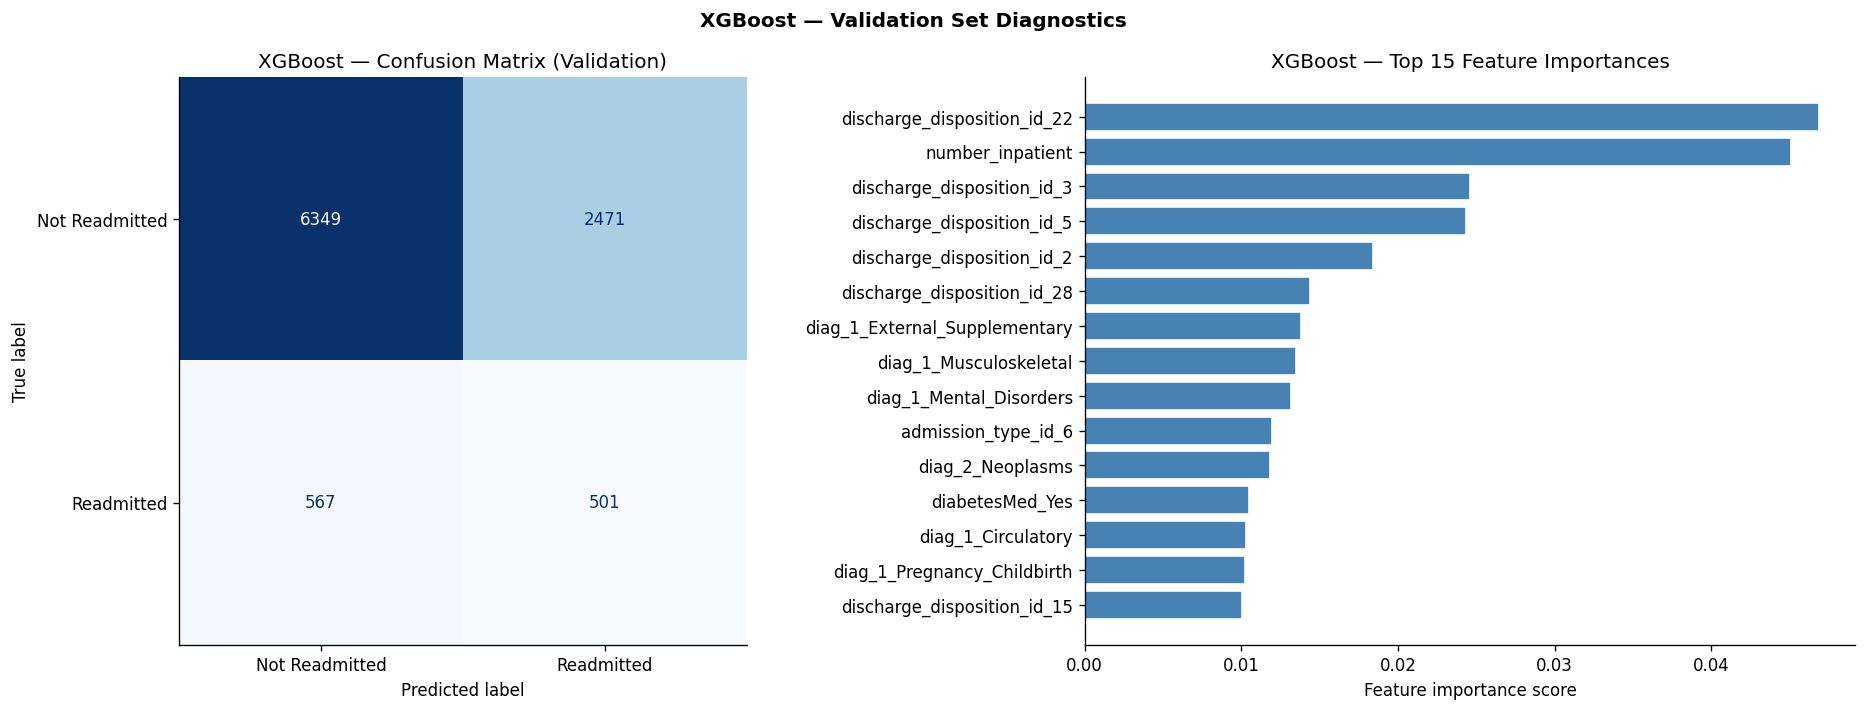

In [53]:
# XGBoost
# scale_pos_weight=imbalance_ratio: XGBoost's equivalent of class_weight
# eval_metric='aucpr': precision-recall AUC — more informative than ROC-AUC
# eval_set: passes both train and val for training curve — no leakage, val is used for monitoring only, not for fitting
xgb = XGBClassifier(
    scale_pos_weight=imbalance_ratio,
    eval_metric='aucpr',
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbosity=0
)

xgb.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    verbose=False
)

# Evaluated on validation set only — test set not touched at this stage
xgb_results = evaluate_model(xgb, X_val, y_val, model_name="XGBoost")

# Two-panel diagnostic: confusion matrix (left) | feature importance (right)
xgb_importance_df = pd.DataFrame({
    'feature':    X_train.columns,
    'importance': xgb.feature_importances_
}).sort_values('importance', ascending=True).tail(15)

fig, (ax_cm, ax_imp) = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('XGBoost — Validation Set Diagnostics', fontweight='bold')

# Left: confusion matrix
y_pred = xgb.predict(X_val)
ConfusionMatrixDisplay.from_predictions(
    y_val, y_pred,
    display_labels=['Not Readmitted', 'Readmitted'],
    colorbar=False,
    cmap='Blues',
    ax=ax_cm
)
ax_cm.set_title('XGBoost — Confusion Matrix (Validation)')

# Right: feature importance
ax_imp.barh(xgb_importance_df['feature'], xgb_importance_df['importance'], edgecolor='white', color='steelblue')
ax_imp.set_title('XGBoost — Top 15 Feature Importances')
ax_imp.set_xlabel('Feature importance score')

plt.tight_layout()
plt.show()

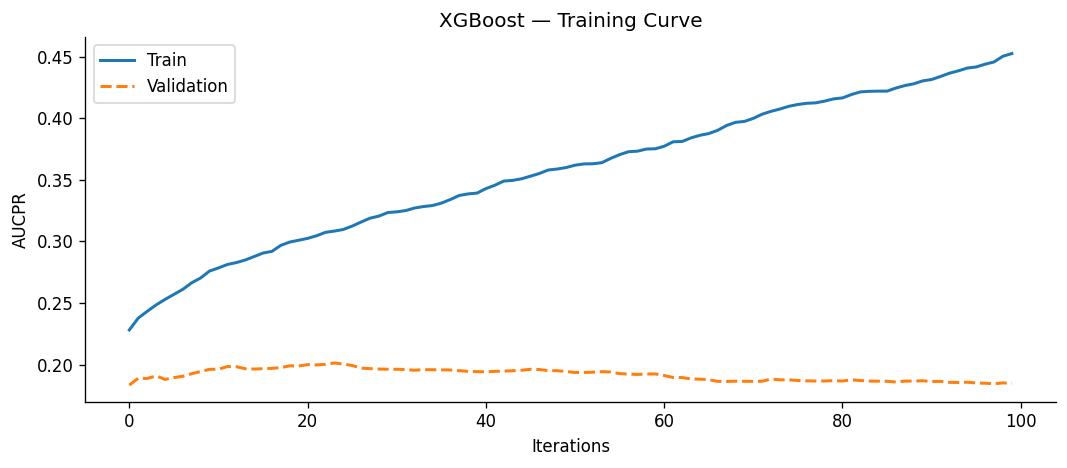

In [54]:
# Training curve
# Widening gap indicates overfitting — model memorising training data
# Val curve declining slightly after plateau suggests early stopping
# would reduce overfitting without sacrificing val performance
results = xgb.evals_result()
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(results['validation_0']['aucpr'], label='Train', linewidth=1.8)
ax.plot(results['validation_1']['aucpr'], label='Validation', linewidth=1.8, linestyle='--')
ax.set_xlabel('Iterations')
ax.set_ylabel('AUCPR')
ax.set_title('XGBoost — Training Curve')
ax.legend()
plt.tight_layout()
plt.show()

### 4.4 MLP Neural Network


MLP Neural Network — Validation Results
  F2-Score  (primary):   0.3701
  ROC-AUC:               0.6490
  Recall (<30d class):   0.5206
  Macro F1:              0.5258

Classification Report:
                precision    recall  f1-score   support

Not Readmitted       0.92      0.70      0.79      8820
    Readmitted       0.17      0.52      0.26      1068

      accuracy                           0.68      9888
     macro avg       0.55      0.61      0.53      9888
  weighted avg       0.84      0.68      0.74      9888



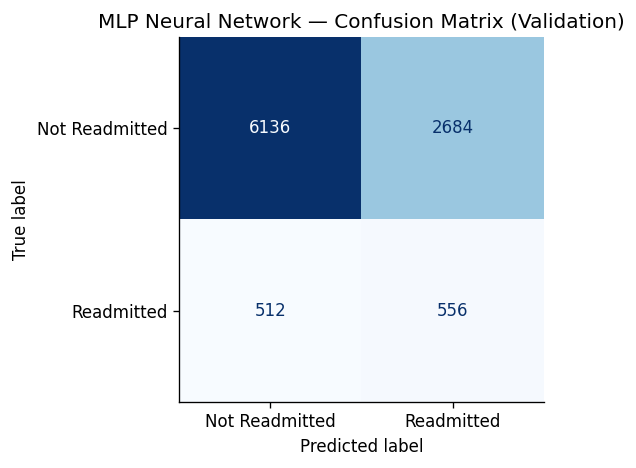

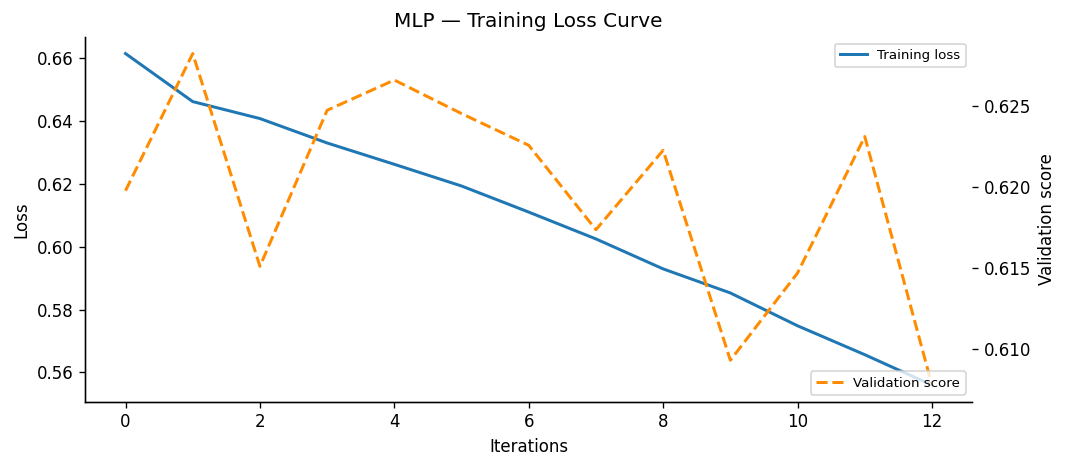

Converged after 13 iterations.


In [55]:
# Simple feedforward network — two hidden layers (128, 64 neurons).
# sample_weight passed to .fit() — equivalent to class_weight for MLP
# early_stopping=True — prevents overfitting on training set

# Compute per-sample weights from CLASS_WEIGHT
sample_weights = y_train.map(class_weight_dict).values

mlp = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    max_iter=200,
    early_stopping=True,
    validation_fraction=0.1,
    random_state=RANDOM_STATE
)

mlp.fit(X_train, y_train, sample_weight=sample_weights)
mlp_results = evaluate_model(mlp, X_val, y_val, model_name="MLP Neural Network")

# Loss curve
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(mlp.loss_curve_, label='Training loss', linewidth=1.8)
if mlp.validation_scores_ is not None:
    ax2 = ax.twinx()
    ax2.plot(mlp.validation_scores_, label='Validation score',
             linewidth=1.8, linestyle='--', color='darkorange')
    ax2.set_ylabel('Validation score')
    ax2.legend(loc='lower right', fontsize=8)
ax.set_xlabel('Iterations')
ax.set_ylabel('Loss')
ax.set_title('MLP — Training Loss Curve')
ax.legend(loc='upper right', fontsize=8)
plt.tight_layout()
plt.show()

print(f"Converged after {mlp.n_iter_} iterations.")



### 4.4 Model Comparison Table

MODEL COMPARISON — Validation Set
                         F2  ROC-AUC  Recall  Macro F1
Model                                                 
Logistic Regression  0.3761   0.6500  0.5440    0.5185
MLP Neural Network   0.3701   0.6490  0.5206    0.5258
XGBoost              0.3458   0.6332  0.4691    0.5275

Primary metric: F2-Score (β=2 — recall weighted 2x over precision)
Best model (highest F2): Logistic Regression


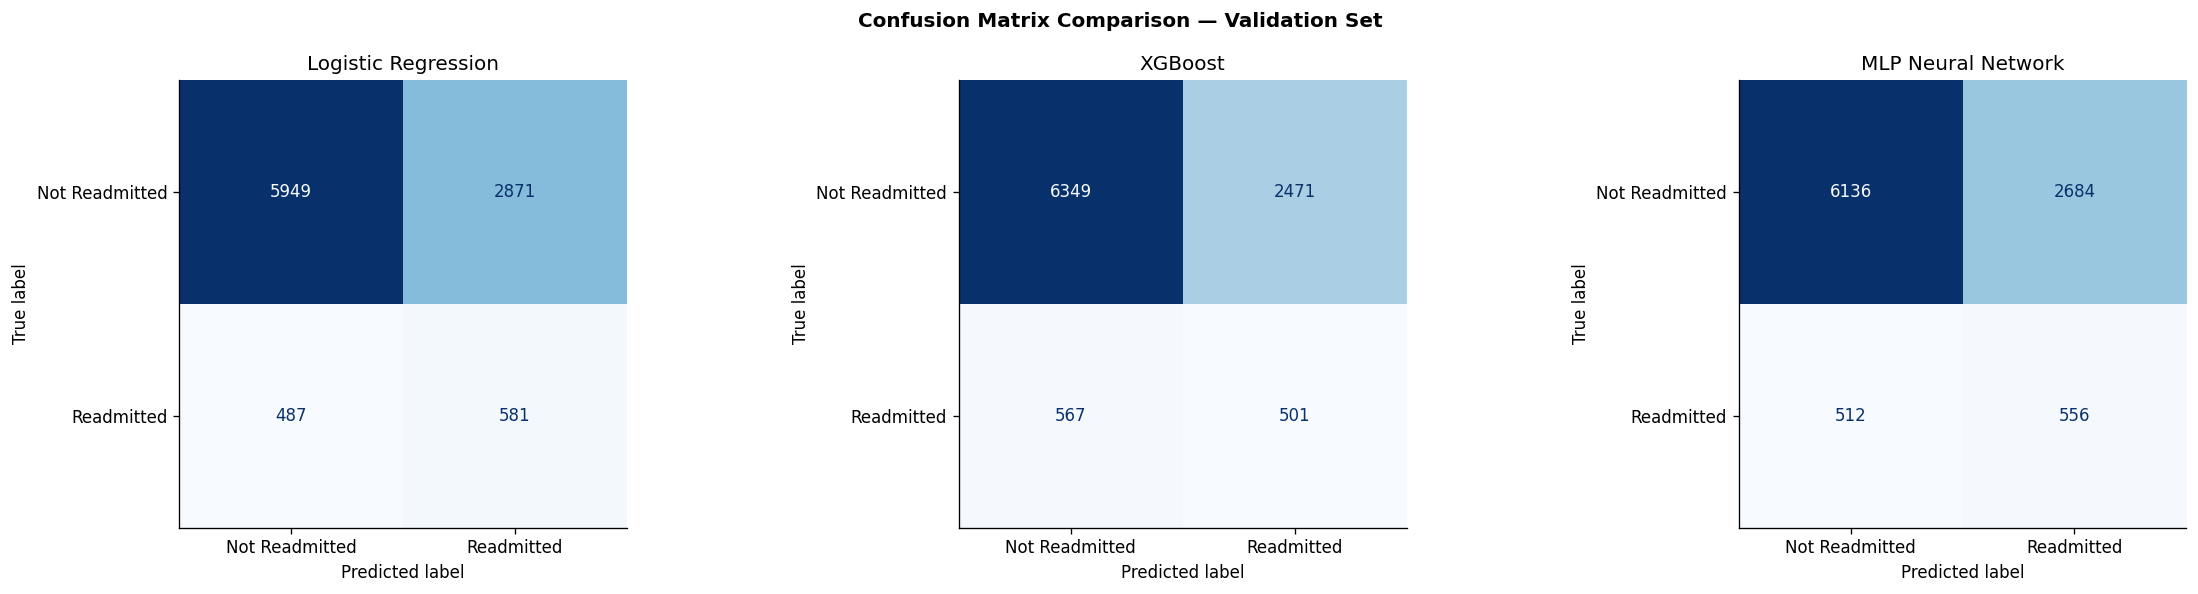

In [56]:
# All three models evaluated on validation set.
# Primary sort: F2-score (approved Step 1 metric).

comparison_df = pd.DataFrame([
    lr_results,
    xgb_results,
    mlp_results
]).set_index('Model').sort_values('F2', ascending=False)

print("=" * 55)
print("MODEL COMPARISON — Validation Set")
print("=" * 55)
print(comparison_df.to_string())
print("\nPrimary metric: F2-Score (β=2 — recall weighted 2x over precision)")
print("Best model (highest F2):", comparison_df['F2'].idxmax())

from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
fig.suptitle('Confusion Matrix Comparison — Validation Set', fontweight='bold')

models = [
    (lr,  'Logistic Regression'),
    (xgb, 'XGBoost'),
    (mlp, 'MLP Neural Network')
]

for ax, (model, name) in zip(axes, models):
    y_pred = model.predict(X_val)
    ConfusionMatrixDisplay.from_predictions(
        y_val, y_pred,
        display_labels=['Not Readmitted', 'Readmitted'],
        colorbar=False,
        cmap='Blues',
        ax=ax
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

In [57]:
# McNemar test — confirms LR is significantly better than XGBoost and MLP
# Uses validation set predictions (never the test set at this stage)
from statsmodels.stats.contingency_tables import mcnemar

def mcnemar_test(y_true, y_pred_a, y_pred_b, name_a, name_b, alpha=0.05):
    correct_a = (y_pred_a == y_true)
    correct_b = (y_pred_b == y_true)
    b = np.sum(correct_a & ~correct_b)
    c = np.sum(~correct_a & correct_b)
    table = [[np.sum(correct_a & correct_b), b],
             [c, np.sum(~correct_a & ~correct_b)]]
    result = mcnemar(table, exact=True if (b + c) < 25 else False)
    sig = result.pvalue < alpha
    print(f"{name_a} vs {name_b}: b={b}, c={c}, "
          f"p={result.pvalue:.4f} — {'SIGNIFICANT' if sig else 'not significant'} at α={alpha}")
    return result.pvalue, sig

lr_pred_val  = lr.predict(X_val)
xgb_pred_val = xgb.predict(X_val)
mlp_pred_val = mlp.predict(X_val)

print("--- McNemar Tests (Validation Set) ---")
mcnemar_test(y_val.values, lr_pred_val, xgb_pred_val, 'LR', 'XGBoost')
mcnemar_test(y_val.values, lr_pred_val, mlp_pred_val, 'LR', 'MLP')
mcnemar_test(y_val.values, xgb_pred_val, mlp_pred_val, 'XGBoost', 'MLP')

--- McNemar Tests (Validation Set) ---
LR vs XGBoost: b=773, c=1093, p=0.0000 — SIGNIFICANT at α=0.05
LR vs MLP: b=453, c=615, p=0.0000 — SIGNIFICANT at α=0.05
XGBoost vs MLP: b=976, c=818, p=0.0002 — SIGNIFICANT at α=0.05


(np.float64(0.00020997038878578308), np.True_)

### 4.5 Comparison Plot

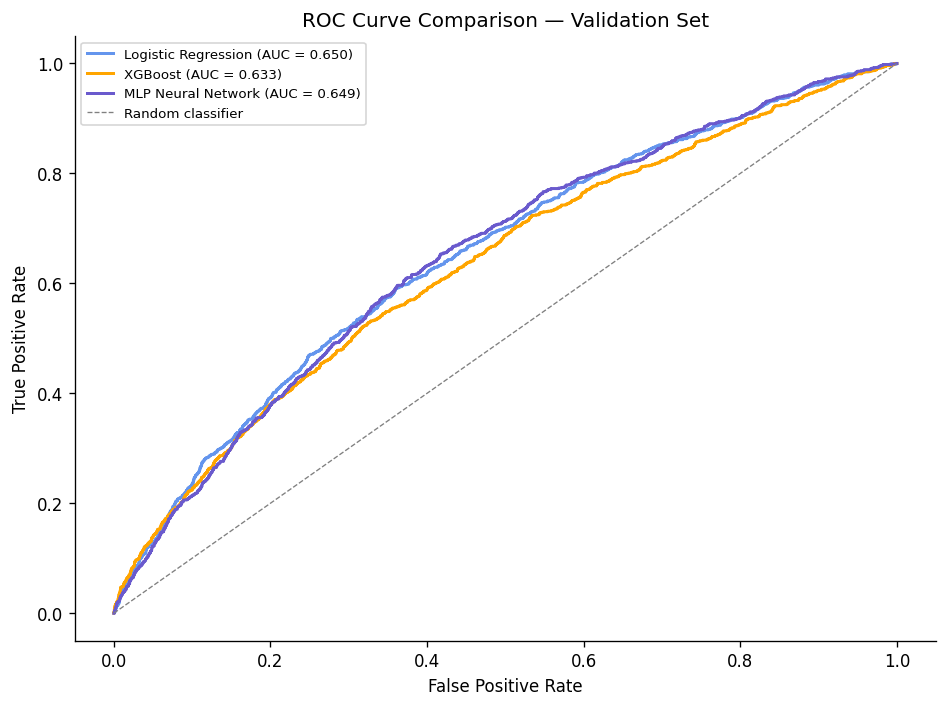

In [58]:
# ROC Curve Comparison of all models (on validation set)
# Random classifier diagonal: AUC=0.5 reference
fig, ax = plt.subplots(figsize=(8, 6))

for model, name, color in [(lr, 'Logistic Regression', 'cornflowerblue'),
                    (xgb, 'XGBoost', 'orange'),
                    (mlp, 'MLP Neural Network', 'slateblue')]:
    y_proba = model.predict_proba(X_val)[:, 1]
    fpr, tpr, _ = roc_curve(y_val, y_proba)
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, linewidth=1.8, color=color, label=f'{name} (AUC = {roc_auc:.3f})')

ax.plot([0, 1], [0, 1], linestyle='--', color='grey', linewidth=0.8, label='Random classifier')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve Comparison — Validation Set')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

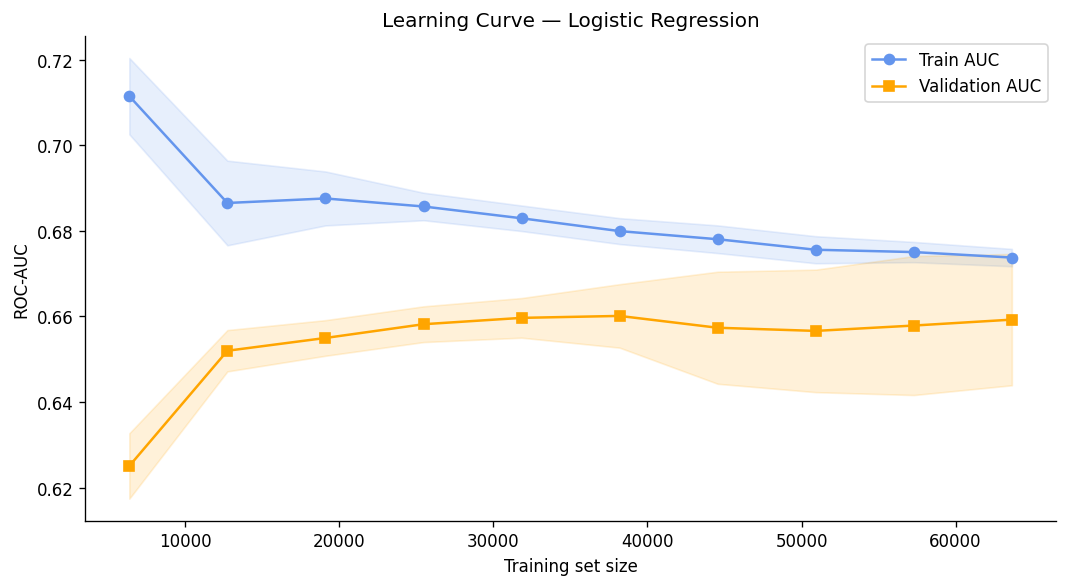

In [59]:
# Learning Curve — overfitting/underfitting diagnostic
# cv=5: 5-fold cross-validation within X_train — X_val and X_test not involved
from sklearn.model_selection import learning_curve

train_sizes, train_scores, val_scores = learning_curve(
    estimator=lr,
    X=X_train, y=y_train,
    cv=5,
    scoring='roc_auc',
    train_sizes=np.linspace(0.1, 1.0, 10),
    n_jobs=-1
)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(train_sizes, train_scores.mean(axis=1), 'o-',
        color='cornflowerblue', label='Train AUC')
ax.fill_between(train_sizes,
                train_scores.mean(1) - train_scores.std(1),
                train_scores.mean(1) + train_scores.std(1),
                alpha=0.15, color='cornflowerblue')
ax.plot(train_sizes, val_scores.mean(axis=1), 's-',
        color='orange', label='Validation AUC')
ax.fill_between(train_sizes,
                val_scores.mean(1) - val_scores.std(1),
                val_scores.mean(1) + val_scores.std(1),
                alpha=0.15, color='orange')
ax.set_xlabel('Training set size')
ax.set_ylabel('ROC-AUC')
ax.set_title('Learning Curve — Logistic Regression')
ax.legend()
plt.tight_layout()
plt.show()

## **Step 5: Threshold Optimisation & Final Evaluation**

### 5.1 Calibration Curve

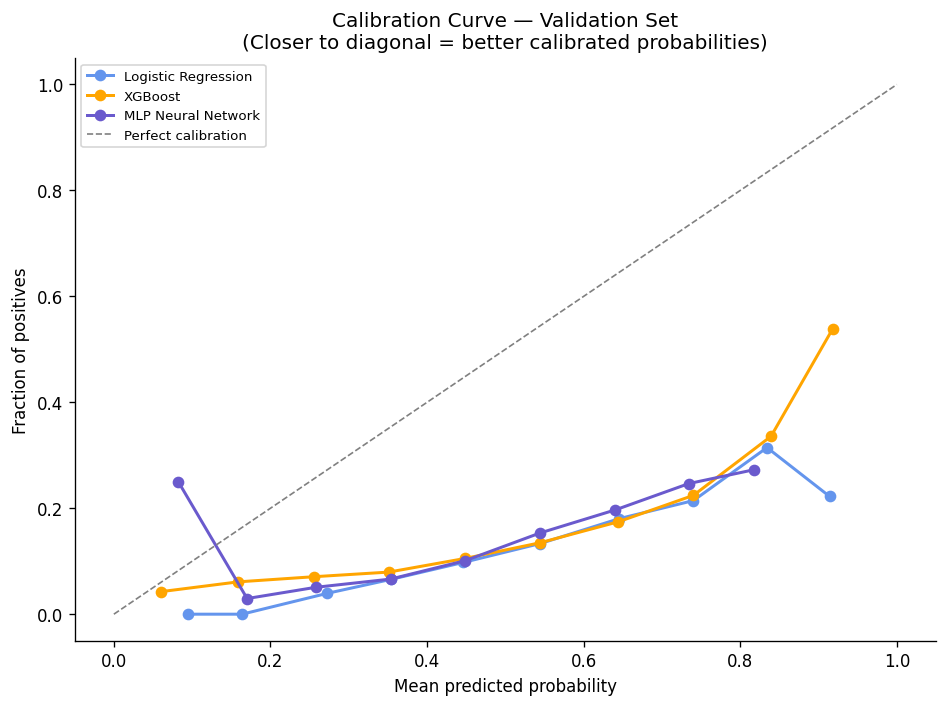

Interpretation:
A model close to the diagonal produces reliable probability estimates.
This justifies using Logistic Regression probabilities for threshold selection.


In [60]:
# Plots mean predicted probability vs actual fraction of positives
# Justifies using its probabilities for threshold selection in 5.2

fig, ax = plt.subplots(figsize=(8, 6))

for model, name, color in [(lr, 'Logistic Regression', 'cornflowerblue'),
                    (xgb, 'XGBoost', 'orange'),
                    (mlp, 'MLP Neural Network', 'slateblue')]:
    y_proba = model.predict_proba(X_val)[:, 1]
    prob_true, prob_pred = calibration_curve(y_val, y_proba, n_bins=10)
    ax.plot(prob_pred, prob_true, marker='o', color=color, linewidth=1.8, label=name)

ax.plot([0, 1], [0, 1], linestyle='--', color='grey',
        linewidth=1.0, label='Perfect calibration')
ax.set_xlabel('Mean predicted probability')
ax.set_ylabel('Fraction of positives')
ax.set_title('Calibration Curve — Validation Set\n'
             '(Closer to diagonal = better calibrated probabilities)')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print("Interpretation:")
print("A model close to the diagonal produces reliable probability estimates.")
print("This justifies using Logistic Regression probabilities for threshold selection.")

### 5.2 Threshold Optimisation + PR Curve

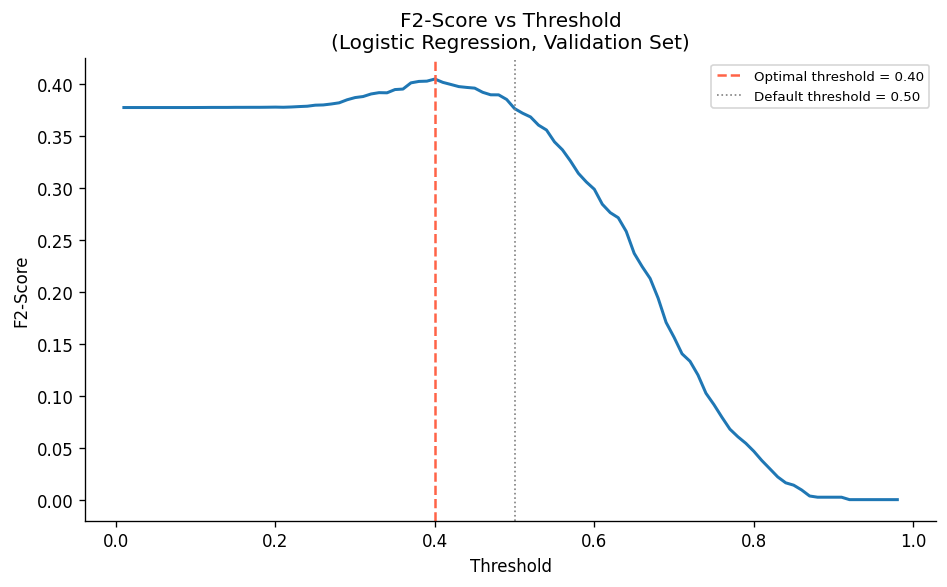

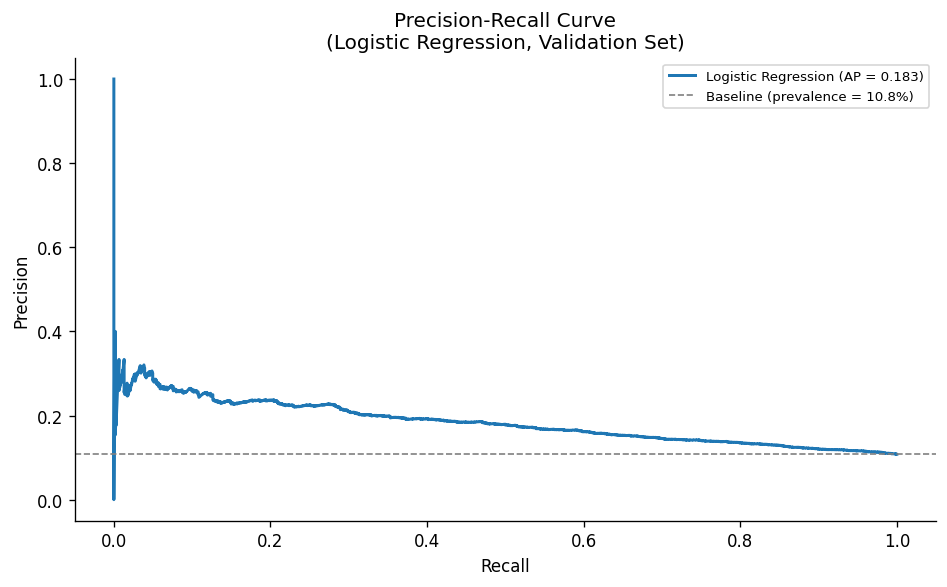

Default threshold (0.50) F2:  0.3761
Optimal threshold (0.40) F2: 0.4045
F2 improvement:               0.0284


In [61]:
# Sweep thresholds 0.01 → 0.99 on VALIDATION SET only.
# Optimal threshold = threshold maximising F2-score.
# Test set never seen at this stage.
lr_proba_val = lr.predict_proba(X_val)[:, 1]

thresholds = np.arange(0.01, 0.99, 0.01)
f2_scores, precisions, recalls = [], [], []

for t in thresholds:
    y_pred_t = (lr_proba_val >= t).astype(int)
    f2_scores.append(fbeta_score(y_val, y_pred_t, beta=2, zero_division=0))
    precisions.append(pd.Series(y_pred_t).eq(1).mean() if y_pred_t.sum() > 0 else 0)
    recalls.append(recall_score(y_val, y_pred_t, zero_division=0))

# Use sklearn precision_recall_curve for the PR curve
sk_precision, sk_recall, sk_thresholds = precision_recall_curve(y_val, lr_proba_val)
ap_score = average_precision_score(y_val, lr_proba_val)

# Optimal threshold
optimal_idx = np.argmax(f2_scores)
OPTIMAL_THRESHOLD = thresholds[optimal_idx]
optimal_f2 = f2_scores[optimal_idx]

# Figure A — F2 vs threshold
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(thresholds, f2_scores, linewidth=1.8)
ax.axvline(OPTIMAL_THRESHOLD, color='tomato', linestyle='--',
           linewidth=1.5, label=f'Optimal threshold = {OPTIMAL_THRESHOLD:.2f}')
ax.axvline(0.5, color='grey', linestyle=':',
           linewidth=1.0, label='Default threshold = 0.50')
ax.set_xlabel('Threshold')
ax.set_ylabel('F2-Score')
ax.set_title('F2-Score vs Threshold\n(Logistic Regression, Validation Set)')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# Figure B — Precision-Recall curve
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(sk_recall, sk_precision, linewidth=1.8,
        label=f'Logistic Regression (AP = {ap_score:.3f})')
ax.axhline(y_val.mean(), color='grey', linestyle='--',
           linewidth=1.0, label=f'Baseline (prevalence = {y_val.mean():.1%})')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curve\n(Logistic Regression, Validation Set)')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"Default threshold (0.50) F2:  {f2_scores[list(thresholds).index(0.50)]:.4f}")
print(f"Optimal threshold ({OPTIMAL_THRESHOLD:.2f}) F2: {optimal_f2:.4f}")
print(f"F2 improvement:               {optimal_f2 - f2_scores[list(thresholds).index(0.50)]:.4f}")

### 5.3 Optimised Model Evaluation - Validation Set

Logistic Regression — Optimised Threshold (0.40)
Validation Set Results
  F2-Score:  0.4045  (vs 0.3761 at default 0.50)
  ROC-AUC:   0.6500
  Recall:    0.7828  (vs 0.5440 at default 0.50)
  Macro F1:  0.4015  (vs 0.5185 at default 0.50)

Classification Report:
                precision    recall  f1-score   support

Not Readmitted       0.94      0.41      0.57      8820
    Readmitted       0.14      0.78      0.23      1068

      accuracy                           0.45      9888
     macro avg       0.54      0.60      0.40      9888
  weighted avg       0.85      0.45      0.53      9888



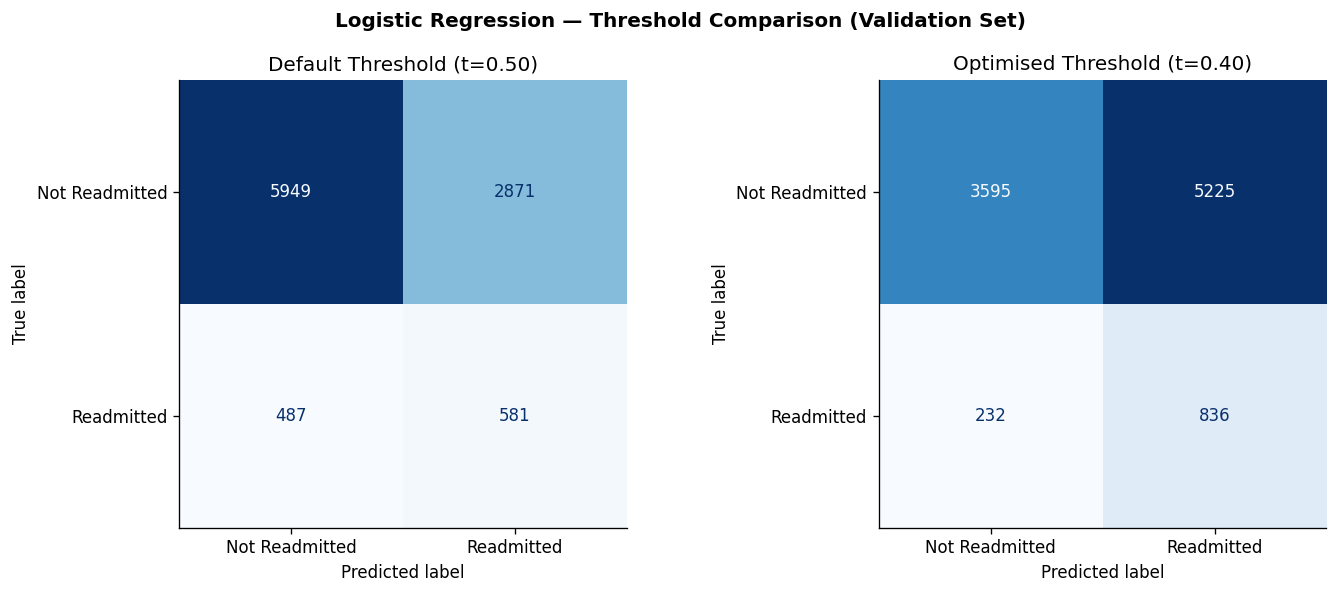

In [62]:
# Logistic Regression at OPTIMAL_THRESHOLD.
# Confirms improvement over default threshold before touching test set.
lr_pred_opt = (lr_proba_val >= OPTIMAL_THRESHOLD).astype(int)
lr_pred_default = lr.predict(X_val)

f2_opt       = fbeta_score(y_val, lr_pred_opt, beta=2)
auc_opt      = roc_auc_score(y_val, lr_proba_val)
recall_opt   = recall_score(y_val, lr_pred_opt)
macro_f1_opt = f1_score(y_val, lr_pred_opt, average='macro')

print(f"{'='*55}")
print(f"Logistic Regression — Optimised Threshold ({OPTIMAL_THRESHOLD:.2f})")
print(f"Validation Set Results")
print(f"{'='*55}")
print(f"  F2-Score:  {f2_opt:.4f}  (vs {fbeta_score(y_val, lr_pred_default, beta=2):.4f} at default 0.50)")
print(f"  ROC-AUC:   {auc_opt:.4f}")
print(f"  Recall:    {recall_opt:.4f}  (vs {recall_score(y_val, lr_pred_default):.4f} at default 0.50)")
print(f"  Macro F1:  {macro_f1_opt:.4f}  (vs {f1_score(y_val, lr_pred_default, average='macro'):.4f} at default 0.50)")
print(f"\nClassification Report:")
print(classification_report(y_val, lr_pred_opt,
                             target_names=['Not Readmitted', 'Readmitted']))

# Two-panel confusion matrix: baseline vs optimised
fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Logistic Regression — Threshold Comparison (Validation Set)', fontweight='bold')

# Left: default threshold
ConfusionMatrixDisplay.from_predictions(
    y_val, lr_pred_default,
    display_labels=['Not Readmitted', 'Readmitted'],
    colorbar=False, cmap='Blues', ax=ax_left
)
ax_left.set_title('Default Threshold (t=0.50)')

# Right: optimised threshold
ConfusionMatrixDisplay.from_predictions(
    y_val, lr_pred_opt,
    display_labels=['Not Readmitted', 'Readmitted'],
    colorbar=False, cmap='Blues', ax=ax_right
)
ax_right.set_title(f'Optimised Threshold (t={OPTIMAL_THRESHOLD:.2f})')

plt.tight_layout()
plt.show()

### 5.4 Final Evaluation - Test Set

In [63]:
print("=" * 55)
print("TEST SET EVALUATION")
print("=" * 55)

# --- Part A: All three models at default threshold ---
test_results = []
test_predictions = {}

for model, name in [(lr, 'Logistic Regression'),
                    (xgb, 'XGBoost'),
                    (mlp, 'MLP Neural Network')]:
    y_pred  = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    test_predictions[name] = {'pred': y_pred, 'proba': y_proba}

    test_results.append({
        'Model':    name,
        'F2':       round(fbeta_score(y_test, y_pred, beta=2), 4),
        'ROC-AUC':  round(roc_auc_score(y_test, y_proba), 4),
        'Recall':   round(recall_score(y_test, y_pred), 4),
        'Macro F1': round(f1_score(y_test, y_pred, average='macro'), 4),
        'Threshold': 0.50
    })
    
   
# --- Part B: Logistic Regression at optimal threshold ---
lr_proba_test = test_predictions['Logistic Regression']['proba']
lr_pred_test_opt = (lr_proba_test >= OPTIMAL_THRESHOLD).astype(int)

test_results.append({
    'Model':    f'Logistic Regression (t={OPTIMAL_THRESHOLD:.2f})',
    'F2':       round(fbeta_score(y_test, lr_pred_test_opt, beta=2), 4),
    'ROC-AUC':  round(roc_auc_score(y_test, lr_proba_test), 4),
    'Recall':   round(recall_score(y_test, lr_pred_test_opt), 4),
    'Macro F1': round(f1_score(y_test, lr_pred_test_opt, average='macro'), 4),
    'Threshold': OPTIMAL_THRESHOLD
})

# --- Part C: Error Analysis ---
# Identify which subgroups the model fails on most
# False negatives = readmitted patients the model missed
# False positives = non-readmitted patients flagged incorrectly
fn = ((lr_pred_test_opt == 0) & (y_test == 1)).sum()
fp = ((lr_pred_test_opt == 1) & (y_test == 0)).sum()
tp = ((lr_pred_test_opt == 1) & (y_test == 1)).sum()
tn = ((lr_pred_test_opt == 0) & (y_test == 0)).sum()

print(f"\n--- Part C: Error Analysis (LR, t={OPTIMAL_THRESHOLD:.2f}) ---")
print(f"True Positives  (correctly flagged):      {tp:,}")
print(f"True Negatives  (correctly cleared):      {tn:,}")
print(f"False Negatives (missed readmissions):    {fn:,}  ← clinical priority")
print(f"False Positives (unnecessary alerts):     {fp:,}")
print(f"\nMissed readmission rate: {fn/(fn+tp):.1%} of all actual readmissions missed")
print(f"False alert rate:        {fp/(fp+tn):.1%} of all actual non-readmissions flagged")


# --- Part D: Subgroup Failure Analysis ---
# Checks model performance on two subgroups identified in EDA (Step 2.8):
# 1. Age group [20-30) — counterintuitive high readmission rate
# 2. Emergency admissions — dominant admission type (56%)

# Reconstruct test set with original categorical columns for subgroup slicing
# Requires X_test_raw — original df rows at test indices before OHE
# If not available, use the index alignment below

test_idx_mask = y_test.index
subgroup_df = df.loc[test_idx_mask].copy()
subgroup_df['y_true'] = y_test.values
subgroup_df['y_pred'] = lr_pred_test_opt
subgroup_df['y_proba'] = lr_proba_test

print(f"\n--- Part D: Subgroup Failure Analysis ---")

# Subgroup 1: Age groups
print("\nF2-Score by age group (LR, optimal threshold):")
age_results = []
for age_group in ['[20-30)', '[30-40)', '[40-50)', '[50-60)',
                  '[60-70)', '[70-80)', '[80-90)', '[90-100)']:
    mask = subgroup_df['age'] == age_group
    if mask.sum() < 10:
        continue
    grp = subgroup_df[mask]
    f2 = fbeta_score(grp['y_true'], grp['y_pred'], beta=2, zero_division=0)
    n  = mask.sum()
    pos_rate = grp['y_true'].mean()
    age_results.append({'Age Group': age_group, 'n': n,
                        'Positive Rate': round(pos_rate, 3), 'F2': round(f2, 4)})

age_results_df = pd.DataFrame(age_results)
print(age_results_df.to_string(index=False))

# Subgroup 2: Admission type
print("\nF2-Score by admission type (LR, optimal threshold):")
ADM_LABELS = {1: 'Emergency', 2: 'Urgent', 3: 'Elective'}
adm_results = []
for adm_id, adm_label in ADM_LABELS.items():
    mask = subgroup_df['admission_type_id'] == adm_id
    if mask.sum() < 10:
        continue
    grp = subgroup_df[mask]
    f2 = fbeta_score(grp['y_true'], grp['y_pred'], beta=2, zero_division=0)
    n  = mask.sum()
    pos_rate = grp['y_true'].mean()
    adm_results.append({'Admission Type': adm_label, 'n': n,
                        'Positive Rate': round(pos_rate, 3), 'F2': round(f2, 4)})

adm_results_df = pd.DataFrame(adm_results)
print(adm_results_df.to_string(index=False))


TEST SET EVALUATION

--- Part C: Error Analysis (LR, t=0.40) ---
True Positives  (correctly flagged):      882
True Negatives  (correctly cleared):      3,623
False Negatives (missed readmissions):    234  ← clinical priority
False Positives (unnecessary alerts):     5,124

Missed readmission rate: 21.0% of all actual readmissions missed
False alert rate:        58.6% of all actual non-readmissions flagged

--- Part D: Subgroup Failure Analysis ---

F2-Score by age group (LR, optimal threshold):
Age Group    n  Positive Rate     F2
  [20-30)  194          0.201 0.6955
  [30-40)  379          0.090 0.3987
  [40-50) 1014          0.124 0.4743
  [50-60) 1688          0.084 0.3629
  [60-70) 2175          0.112 0.4131
  [70-80) 2474          0.120 0.4228
  [80-90) 1605          0.128 0.4167
 [90-100)  259          0.104 0.3704

F2-Score by admission type (LR, optimal threshold):
Admission Type    n  Positive Rate     F2
     Emergency 5199          0.116 0.4215
        Urgent 1749          

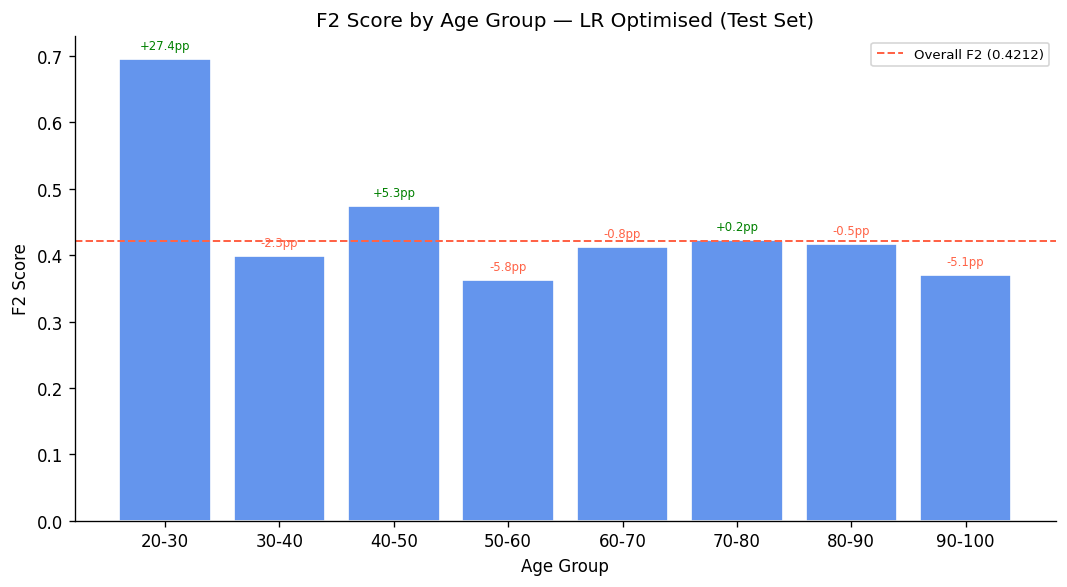

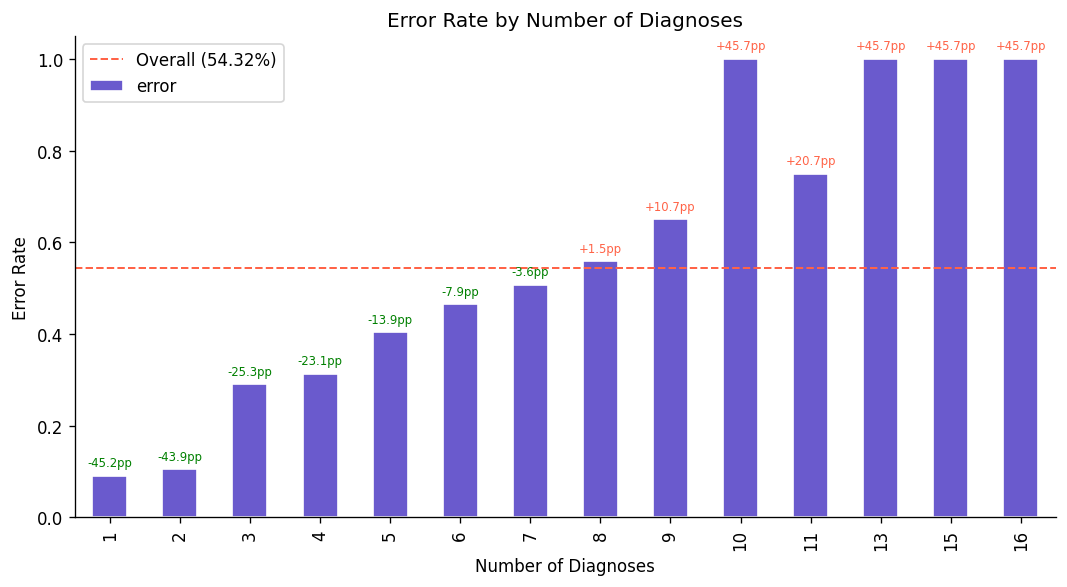

In [64]:
# Recover original categorical columns using y_test index
test_meta = df.loc[y_test.index].copy()

# Compute overall metrics directly — no dependency on summary_df
y_pred_opt = (lr.predict_proba(X_test)[:, 1] >= OPTIMAL_THRESHOLD).astype(int)
overall_f2 = fbeta_score(y_test, y_pred_opt, beta=2)
overall_error = (y_test.values != y_pred_opt).mean()

# Error slice
error_df = pd.DataFrame({
    'true':             y_test.values,
    'pred':             y_pred_opt,
    'age':              test_meta['age'].values,
    'number_diagnoses': df.loc[y_test.index, 'number_diagnoses'].values
})
error_df['error'] = (error_df['true'] != error_df['pred']).astype(int)

# Figure 19 — F2 by age group
age_labels = age_results_df['Age Group'].str.replace(r'[\[\)]', '', regex=True)
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(age_labels, age_results_df['F2'],
              color='cornflowerblue', edgecolor='white')
ax.axhline(overall_f2, color='tomato', linestyle='--', linewidth=1.2,
           label=f'Overall F2 ({overall_f2:.4f})')

for bar, f2 in zip(bars, age_results_df['F2']):
    diff = f2 - overall_f2
    sign = '+' if diff >= 0 else ''
    ax.annotate(f'{sign}{diff*100:.1f}pp',
                xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 4), textcoords='offset points',
                ha='center', va='bottom', fontsize=7,
                color='green' if diff >= 0 else 'tomato')

ax.set_xlabel('Age Group')
ax.set_ylabel('F2 Score')
ax.set_title('F2 Score by Age Group — LR Optimised (Test Set)')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# Figure 20 — Error rate by number of diagnoses
err_diag = error_df.groupby('number_diagnoses')['error'].mean()
fig, ax = plt.subplots(figsize=(9, 5))
err_diag.plot(kind='bar', ax=ax, color='slateblue', edgecolor='white')
ax.axhline(overall_error, color='tomato', linestyle='--', linewidth=1.2,
           label=f'Overall ({overall_error:.2%})')

for bar, err in zip(ax.patches, err_diag):
    diff = err - overall_error
    sign = '+' if diff >= 0 else ''
    ax.annotate(f'{sign}{diff*100:.1f}pp',
                xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 4), textcoords='offset points',
                ha='center', va='bottom', fontsize=7,
                color='tomato' if diff >= 0 else 'green')

ax.set_title('Error Rate by Number of Diagnoses')
ax.set_ylabel('Error Rate')
ax.set_xlabel('Number of Diagnoses')
ax.legend()
plt.tight_layout()
plt.show()

### 5.5 Test Set Summary Table

                                  F2  ROC-AUC  Recall  Macro F1
Model                                                          
Logistic Regression           0.4022   0.6633  0.5717    0.5300
Logistic Regression (t=0.40)  0.4212   0.6633  0.7903    0.4113

F2 improvement: 0.0190


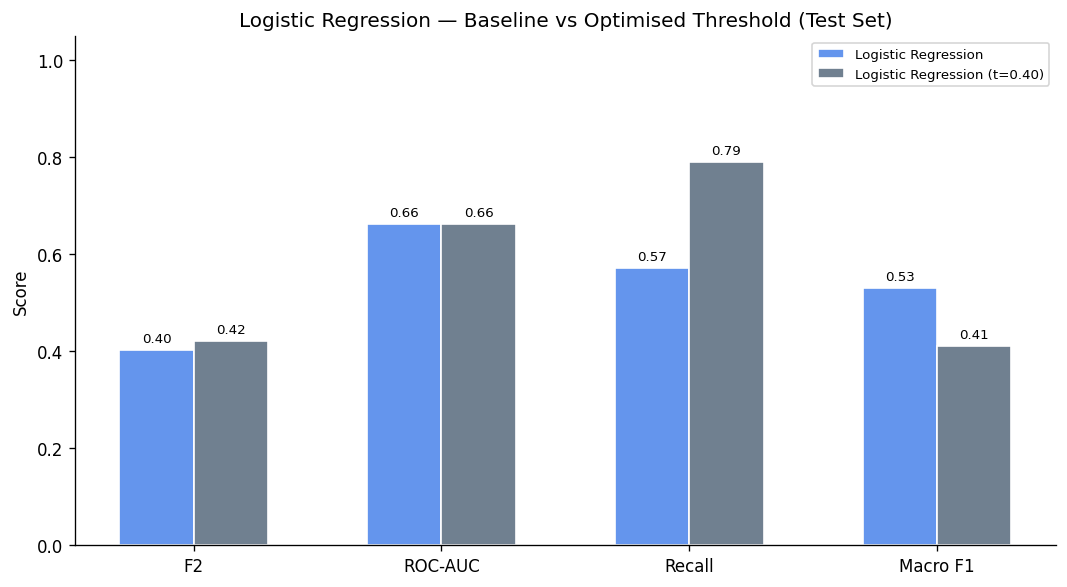

In [65]:
# Test set comparison — LR baseline (t=0.50) vs LR optimised (t=0.40)
summary_df = pd.DataFrame(test_results).set_index('Model')

lr_compare_df = summary_df.loc[
    summary_df.index.isin(['Logistic Regression',
                           f'Logistic Regression (t={OPTIMAL_THRESHOLD:.2f})'])
]

print(lr_compare_df[['F2', 'ROC-AUC', 'Recall', 'Macro F1']].to_string())
print(f"\nF2 improvement: {lr_compare_df['F2'].max() - lr_compare_df['F2'].min():.4f}")

# Figure 18 — LR baseline vs optimised (test set)
fig, ax = plt.subplots(figsize=(9, 5))
metrics = ['F2', 'ROC-AUC', 'Recall', 'Macro F1']
x = np.arange(len(metrics))
width = 0.3
colors = ['cornflowerblue', 'slategrey']

for i, (idx, row) in enumerate(lr_compare_df.iterrows()):
    values = [row[m] for m in metrics]
    bars = ax.bar(x + i * width, values,
                  width, label=idx, color=colors[i], edgecolor='white')
    for bar, val in zip(bars, values):
        ax.annotate(f'{val:.2f}',
                    xy=(bar.get_x() + bar.get_width() / 2, val),
                    xytext=(0, 3), textcoords='offset points',
                    ha='center', va='bottom', fontsize=8)

ax.set_xticks(x + width / 2)
ax.set_xticklabels(metrics)
ax.set_ylabel('Score')
ax.set_title('Logistic Regression — Baseline vs Optimised Threshold (Test Set)')
ax.legend(fontsize=8)
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

## **6. Final Solution**

In [66]:
# Model card — LR final solution (test set)
lr_pred_test_default = (lr_proba_test >= 0.50).astype(int)

summary = {
    'Model':                          'Logistic Regression',
    'Class weights':                  class_weight_dict,
    'Training data':                  'UCI Diabetes 130-US Hospitals (1999-2008)',
    'Analytical cohort':              f'{len(df):,} encounters (post-exclusion)',
    'Features':                       X_test.shape[1],
    'Test set size':                  len(y_test),
    'Split method':                   'GroupShuffleSplit by patient_nbr',
    # Default threshold
    'F2 (t=0.50)':                   round(fbeta_score(y_test, lr_pred_test_default, beta=2), 4),
    'Recall (t=0.50)':               round(recall_score(y_test, lr_pred_test_default), 4),
    'Precision (t=0.50)':            round(precision_score(y_test, lr_pred_test_default, zero_division=0), 4),
    'ROC-AUC (t=0.50)':             round(roc_auc_score(y_test, lr_proba_test), 4),
    # Optimised threshold
    f'F2 (t={OPTIMAL_THRESHOLD:.2f})':        round(fbeta_score(y_test, lr_pred_test_opt, beta=2), 4),
    f'Recall (t={OPTIMAL_THRESHOLD:.2f})':    round(recall_score(y_test, lr_pred_test_opt), 4),
    f'Precision (t={OPTIMAL_THRESHOLD:.2f})': round(precision_score(y_test, lr_pred_test_opt, zero_division=0), 4),
    f'ROC-AUC (t={OPTIMAL_THRESHOLD:.2f})':  round(roc_auc_score(y_test, lr_proba_test), 4),
    # Caveats
    'Intended use':                   'Flag diabetic inpatients at high risk of 30-day readmission at discharge',
    'Not intended for':               'Replacement of clinical judgement; non-US populations without revalidation',
    'Failure modes':                  'Performance degrades with age and diagnostic complexity',
}

for key, value in summary.items():
    print(f"{key:<45} {value}")

Model                                         Logistic Regression
Class weights                                 {0: np.float64(0.5642), 1: np.float64(4.3935)}
Training data                                 UCI Diabetes 130-US Hospitals (1999-2008)
Analytical cohort                             99,319 encounters (post-exclusion)
Features                                      136
Test set size                                 9863
Split method                                  GroupShuffleSplit by patient_nbr
F2 (t=0.50)                                   0.4022
Recall (t=0.50)                               0.5717
Precision (t=0.50)                            0.184
ROC-AUC (t=0.50)                              0.6633
F2 (t=0.40)                                   0.4212
Recall (t=0.40)                               0.7903
Precision (t=0.40)                            0.1469
ROC-AUC (t=0.40)                              0.6633
Intended use                                  Flag diabetic inpatient